# BankScope – Financial Analysis

## Beyond the Balance Sheet

This notebook examines the financial characteristics of banks using FDIC quarterly financial data for Q1 2026 and Q2 2026.

The analysis focuses on bank size, assets, liabilities, deposits, equity, and profitability. It aims to understand financial patterns, compare institutions, and examine changes across the two reporting periods.

### Objectives
- Analyze the distribution of major financial variables.
- Understand differences in bank size and financial structure.
- Examine profitability indicators.
- Compare financial metrics between Q1 and Q2 2026.
- Identify meaningful financial patterns and observations.

## 1. Financial Metric Preparation

This section selects the financial variables required for the analysis and prepares a working dataset for Q1 and Q2 2026.

The original quarterly datasets are preserved. Any additional calculations will be performed on separate working copies.

## 1. Data Loading

The Q1 2026 and Q2 2026 FDIC datasets are loaded into the notebook for financial analysis.

In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path("../data/raw")

q1 = pd.read_csv(DATA_DIR / "Q1.csv")
q2 = pd.read_csv(DATA_DIR / "Q2.csv")

print("Q1 2026 Shape:", q1.shape)
print("Q2 2026 Shape:", q2.shape)

Q1 2026 Shape: (4288, 161)
Q2 2026 Shape: (4247, 161)


In [4]:
financial_columns = [
    "CERT", "NAME", "BKCLASS",
    "ASSET", "LIAB", "DEP", "EQ",
    "NETINC", "ROA", "ROE", "NIM"
]

q1_financial = q1[financial_columns].copy()
q2_financial = q2[financial_columns].copy()

print("Q1 Financial Dataset:", q1_financial.shape)
print("Q2 Financial Dataset:", q2_financial.shape)

display(q2_financial.head())

Q1 Financial Dataset: (4288, 11)
Q2 Financial Dataset: (4247, 11)


,CERT,NAME,BKCLASS,ASSET,LIAB,DEP,EQ,NETINC,ROA,ROE,NIM
0,14,STATE STREET BANK&TRUST CO,SM,412620000,383448000,326247000,29172000.0,1875000.0,0.969956,12.96,1828000.0
1,35,AUBURNBANK,SM,1085002,994121,990462,90881.0,4609.0,0.883621,10.15,15652.0
2,39,ROBERTSON BANKING CO,NM,462662,411609,399516,51053.0,4784.0,2.041271,19.34,9398.0
3,41,PHENIX-GIRARD BANK,NM,342259,333299,323551,8960.0,1794.0,1.043623,43.88,4660.0
4,49,BANK OF EVERGREEN,NM,78111,69019,68562,9092.0,259.0,0.670782,5.76,1237.0


## 2. Descriptive Statistics of Financial Variables

This section examines the central tendency, spread, and range of major financial variables across Q1 and Q2 2026.

Descriptive statistics help us understand the distribution of bank assets, liabilities, deposits, equity, and profitability indicators before conducting further analysis.

In [5]:
financial_metrics = [
    "ASSET", "LIAB", "DEP", "EQ",
    "NETINC", "ROA", "ROE"
]

print("Q1 2026 Financial Summary")
display(q1_financial[financial_metrics].describe().T.round(2))

print("\nQ2 2026 Financial Summary")
display(q2_financial[financial_metrics].describe().T.round(2))

Q1 2026 Financial Summary


,count,mean,std,min,25%,50%,75%,max
ASSET,4288.0,6124552.36,89010022.47,3490.00,170181.75,384477.50,975237.75,4.016571e+09
LIAB,4288.0,5513012.97,81100418.70,93.00,148476.25,343482.50,868753.50,3.680610e+09
DEP,4288.0,4807692.02,66531441.79,0.00,143635.50,327035.50,825104.75,2.787994e+09
EQ,4279.0,612179.18,7973407.04,-17116.00,18216.50,39996.00,104521.00,3.359310e+08
NETINC,4279.0,18801.96,283794.46,-131902.00,377.50,1082.00,2991.50,1.397400e+07
ROA,4288.0,1.22,2.40,-38.54,0.76,1.18,1.60,8.143000e+01
ROE,4278.0,10.94,14.33,-385.62,6.98,11.22,15.34,2.115400e+02



Q2 2026 Financial Summary


,count,mean,std,min,25%,50%,75%,max
ASSET,4247.0,6259320.83,90741440.66,3489.00,173010.00,388108.00,992939.50,4.091315e+09
LIAB,4247.0,5640640.60,82762789.16,501.00,149786.00,345930.00,888168.50,3.749705e+09
DEP,4247.0,4896375.78,67637008.79,124.00,144353.50,327579.00,831053.50,2.820284e+09
EQ,4238.0,619354.97,8040919.96,-23485.00,18905.25,41180.50,107628.00,3.415800e+08
NETINC,4238.0,40246.40,619770.16,-152251.00,816.00,2293.00,6358.00,3.133500e+07
ROA,4247.0,1.29,2.62,-53.11,0.82,1.22,1.64,8.114000e+01
ROE,4237.0,11.49,11.13,-228.84,7.57,11.56,15.71,1.226200e+02


In [6]:
display(
    q2_financial[["ROE"]]
    .describe()
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
ROE,4237.0,11.49,11.13,-228.84,7.57,11.56,15.71,122.62


## 3. Quarter-over-Quarter Comparison of Matched Banks

This section identifies institutions present in both Q1 and Q2 2026 and compares their financial metrics.

Using matched institutions helps reduce the effect of changes in dataset composition and provides a more consistent basis for examining quarterly financial movements.

In [7]:
# Identify institutions present in both quarters
common_certs = set(q1_financial["CERT"]) & set(q2_financial["CERT"])

q1_matched = (
    q1_financial[q1_financial["CERT"].isin(common_certs)]
    .copy()
    .sort_values("CERT")
    .reset_index(drop=True)
)

q2_matched = (
    q2_financial[q2_financial["CERT"].isin(common_certs)]
    .copy()
    .sort_values("CERT")
    .reset_index(drop=True)
)

print("Matched institutions:", len(common_certs))
print("Q1 matched dataset:", q1_matched.shape)
print("Q2 matched dataset:", q2_matched.shape)

Matched institutions: 4243
Q1 matched dataset: (4243, 11)
Q2 matched dataset: (4243, 11)


## 4. Financial Changes Among Matched Institutions

This section measures the quarter-over-quarter changes in financial metrics for the 4,243 institutions present in both reporting periods.

Comparing the same institutions provides a more consistent view of changes in assets, liabilities, deposits, equity, and profitability indicators.

In [8]:
# Financial metrics to compare
comparison_metrics = [
    "ASSET", "LIAB", "DEP", "EQ",
    "NETINC", "ROA", "ROE"
]

# Create a comparison table
comparison = pd.DataFrame({
    "CERT": q1_matched["CERT"],
    "NAME": q1_matched["NAME"]
})

for metric in comparison_metrics:
    comparison[f"{metric}_Q1"] = q1_matched[metric]
    comparison[f"{metric}_Q2"] = q2_matched[metric]
    comparison[f"{metric}_CHANGE"] = (
        comparison[f"{metric}_Q2"] -
        comparison[f"{metric}_Q1"]
    )

display(comparison.head())
print("Comparison dataset shape:", comparison.shape)

,CERT,NAME,ASSET_Q1,ASSET_Q2,ASSET_CHANGE,LIAB_Q1,LIAB_Q2,LIAB_CHANGE,DEP_Q1,DEP_Q2,...,EQ_CHANGE,NETINC_Q1,NETINC_Q2,NETINC_CHANGE,ROA_Q1,ROA_Q2,ROA_CHANGE,ROE_Q1,ROE_Q2,ROE_CHANGE
0,14,STATE STREET BANK&TRUST CO,386546000,412620000,26074000,357835000,383448000,25613000,299560000,326247000,...,461000.0,760000.0,1875000.0,1115000.0,0.813675,0.969956,0.156280,10.55,12.96,2.41
1,35,AUBURNBANK,1026359,1085002,58643,935547,994121,58574,932742,990462,...,69.0,2244.0,4609.0,2365.0,0.878012,0.883621,0.005610,9.89,10.15,0.26
2,39,ROBERTSON BANKING CO,475203,462662,-12541,425889,411609,-14280,413964,399516,...,1739.0,2512.0,4784.0,2272.0,2.129894,2.041271,-0.088624,20.65,19.34,-1.31
3,41,PHENIX-GIRARD BANK,343760,342259,-1501,336992,333299,-3693,327418,323551,...,2192.0,690.0,1794.0,1104.0,0.800989,1.043623,0.242634,35.46,43.88,8.42
4,49,BANK OF EVERGREEN,76245,78111,1866,67317,69019,1702,67039,68562,...,164.0,101.0,259.0,158.0,0.526182,0.670782,0.144600,4.52,5.76,1.24


Comparison dataset shape: (4243, 23)


## 5. Distribution of Quarterly Financial Changes

This section summarizes the financial changes observed across matched institutions.

For each metric, institutions are classified according to whether their values increased, decreased, or remained unchanged between Q1 and Q2 2026.

Median changes are also calculated to reduce the influence of unusually large institutions and extreme observations.

In [9]:
change_summary = []

for metric in comparison_metrics:
    change = comparison[f"{metric}_CHANGE"].dropna()

    change_summary.append({
        "Metric": metric,
        "Institutions Analyzed": len(change),
        "Increased": (change > 0).sum(),
        "Decreased": (change < 0).sum(),
        "Unchanged": (change == 0).sum(),
        "Median Change": change.median(),
        "Mean Change": change.mean()
    })

change_summary_df = pd.DataFrame(change_summary)

display(change_summary_df.round(2))

,Metric,Institutions Analyzed,Increased,Decreased,Unchanged,Median Change,Mean Change
0,ASSET,4243,2473,1769,1,1406.00,94098.71
1,LIAB,4243,2296,1946,1,691.00,90592.99
2,DEP,4243,2161,2062,20,120.00,57389.60
3,EQ,4234,3640,590,4,750.50,3526.79
4,NETINC,4234,4056,178,0,1194.50,21302.89
5,ROA,4243,2855,1379,9,0.04,0.07
6,ROE,4233,2724,1485,24,0.34,0.33


In [10]:
print(change_summary_df.to_string(index=False))

Metric  Institutions Analyzed  Increased  Decreased  Unchanged  Median Change  Mean Change
 ASSET                   4243       2473       1769          1    1406.000000 94098.706576
  LIAB                   4243       2296       1946          1     691.000000 90592.988923
   DEP                   4243       2161       2062         20     120.000000 57389.597690
    EQ                   4234       3640        590          4     750.500000  3526.790269
NETINC                   4234       4056        178          0    1194.500000 21302.888758
   ROA                   4243       2855       1379          9       0.041262     0.072729
   ROE                   4233       2724       1485         24       0.340000     0.326660


## 6. Distribution of Financial Changes

This section visualizes the number of matched institutions experiencing increases, decreases, or no change in each financial metric between Q1 and Q2 2026.

The visualization helps identify which financial indicators showed the strongest upward or downward patterns.

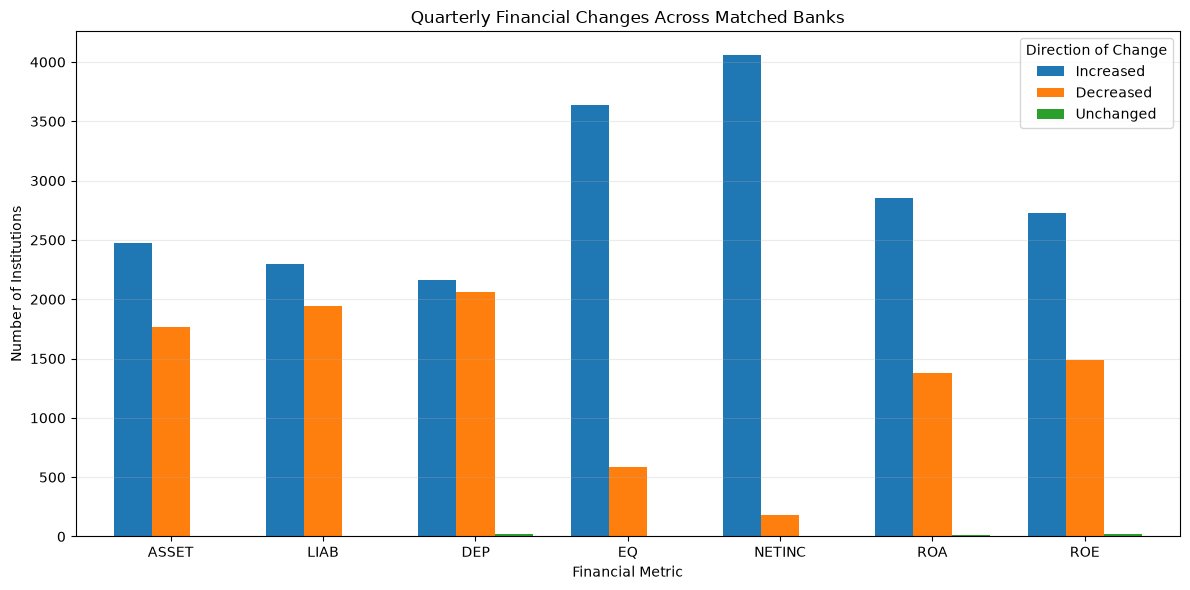

In [11]:
import matplotlib.pyplot as plt

plot_data = change_summary_df.set_index("Metric")[
    ["Increased", "Decreased", "Unchanged"]
]

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

plt.title("Quarterly Financial Changes Across Matched Banks")
plt.xlabel("Financial Metric")
plt.ylabel("Number of Institutions")
plt.xticks(rotation=0)
plt.legend(title="Direction of Change")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Key Observations

- Net income recorded the strongest upward pattern, with 4,056 out of 4,234 institutions showing an increase.
- Equity increased for 3,640 out of 4,234 institutions.
- Deposit changes were relatively balanced, indicating that increases and decreases occurred in similar numbers.
- Assets and liabilities showed moderately higher counts of increases than decreases.
- ROA and ROE increased for more institutions than they decreased.

Overall, the matched-institution comparison indicates a broadly positive direction in several financial indicators during Q2 2026. However, these observations represent short-term quarterly changes and should not be interpreted as evidence of long-term financial stability.

## 7. Percentage Change Analysis

Absolute changes show the numerical difference between Q1 and Q2, while percentage changes show the relative size of that difference.

This section examines the percentage changes in assets, liabilities, deposits, and equity across matched institutions.

Percentage changes will only be calculated when the Q1 starting value is positive. Zero and negative starting values will be excluded to avoid misleading percentage calculations.

In [12]:
percentage_metrics = ["ASSET", "LIAB", "DEP", "EQ"]

for metric in percentage_metrics:
    q1_values = comparison[f"{metric}_Q1"]
    q2_values = comparison[f"{metric}_Q2"]

    valid = q1_values > 0

    comparison[f"{metric}_PCT_CHANGE"] = np.nan

    comparison.loc[valid, f"{metric}_PCT_CHANGE"] = (
        (q2_values[valid] - q1_values[valid])
        / q1_values[valid]
    ) * 100

# Summarize percentage changes
percentage_summary = comparison[
    [f"{metric}_PCT_CHANGE" for metric in percentage_metrics]
].describe().T

percentage_summary.index = percentage_metrics

display(percentage_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
ASSET,4243.0,1.38,17.77,-47.22,-1.17,0.52,2.41,1078.16
LIAB,4243.0,1.89,41.59,-93.98,-1.59,0.31,2.43,2528.38
DEP,4243.0,2.15,83.44,-94.78,-1.82,0.06,2.18,5385.29
EQ,4233.0,5.83,184.87,-72.56,0.83,2.07,3.36,11994.57


## 8. Distribution of Percentage Changes

This section uses boxplots to compare the distribution of percentage changes in assets, liabilities, deposits, and equity.

The visualization highlights the median, interquartile range, and potential extreme observations across matched institutions.

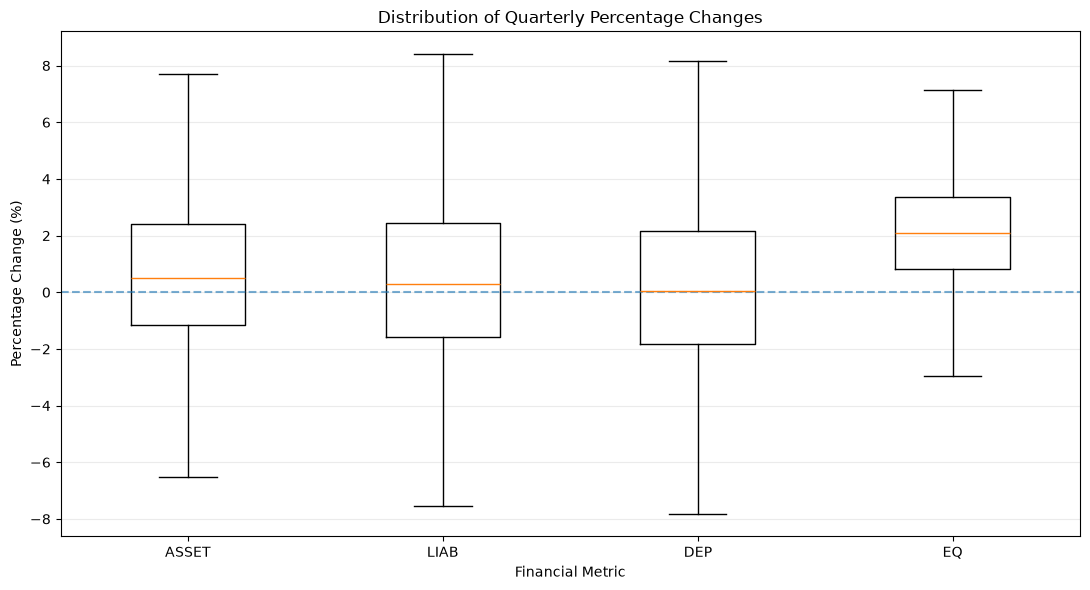

In [14]:
plt.figure(figsize=(11, 6))

box_data = [
    comparison[f"{metric}_PCT_CHANGE"].dropna()
    for metric in percentage_metrics
]

plt.boxplot(
    box_data,
    tick_labels=percentage_metrics,
    showfliers=False
)

plt.title("Distribution of Quarterly Percentage Changes")
plt.xlabel("Financial Metric")
plt.ylabel("Percentage Change (%)")
plt.axhline(y=0, linestyle="--", alpha=0.6)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Key Observations

- Asset, liability, and deposit percentage changes are centred relatively close to zero, indicating modest changes for the typical institution.
- Deposit changes show a nearly balanced distribution around zero.
- Equity has a higher median percentage change than the other three financial metrics.
- The distributions show variation across institutions, with some experiencing substantial increases or decreases.
- Extreme observations are hidden in the boxplot to improve readability but remain part of the underlying analysis.

Overall, equity demonstrates a stronger positive relative movement, while assets, liabilities, and deposits show comparatively modest changes between the two quarters.

## 9. Institutions with the Largest Asset Changes

This section identifies institutions with the largest increases and decreases in total assets between Q1 and Q2 2026.

Examining individual institutions helps identify significant changes that may influence the overall financial trends observed in the matched-bank analysis.

In [15]:
# Top 10 institutions with the largest asset increases
top_asset_increases = comparison.sort_values(
    by="ASSET_CHANGE",
    ascending=False
)[
    ["CERT", "NAME", "ASSET_Q1", "ASSET_Q2", "ASSET_CHANGE"]
].head(10)

# Top 10 institutions with the largest asset decreases
top_asset_decreases = comparison.sort_values(
    by="ASSET_CHANGE",
    ascending=True
)[
    ["CERT", "NAME", "ASSET_Q1", "ASSET_Q2", "ASSET_CHANGE"]
].head(10)

print("Top 10 Asset Increases")
display(top_asset_increases)

print("Top 10 Asset Decreases")
display(top_asset_decreases)

Top 10 Asset Increases


,CERT,NAME,ASSET_Q1,ASSET_Q2,ASSET_CHANGE
102,628,JPMORGAN CHASE BANK NA,4016571000,4091315000,74744000
480,3511,WELLS FARGO BANK NA,1852239000,1907928000,55689000
941,7213,CITIBANK NATIONAL ASSN,1933622000,1976180000,42558000
881,6384,PNC BANK NATIONAL ASSN,567948516,609771726,41823210
3523,32992,MORGAN STANLEY BANK NA,391305000,419318000,28013000
0,14,STATE STREET BANK&TRUST CO,386546000,412620000,26074000
890,6548,U S BANK NATIONAL ASSN,683379960,705554946,22174986
3613,34221,MORGAN STANLEY PRIVATE BK NA,241388000,250425000,9037000
3143,28359,OCEANFIRST BANK NA,14471195,23172826,8701631
3870,57450,CHARLES SCHWAB BANK SSB,242914000,250828000,7914000


Top 10 Asset Decreases


,CERT,NAME,ASSET_Q1,ASSET_Q2,ASSET_CHANGE
103,639,BANK OF NEW YORK MELLON,467349000,425115000,-42234000
479,3510,BANK OF AMERICA NA,2672192000,2654645000,-17547000
612,4297,CAPITAL ONE NATIONAL ASSN,672010000,662157000,-9853000
3069,27471,AMERICAN EXPRESS NB,217568586,213946192,-3622394
3489,32188,USAA FEDERAL SAVINGS BANK,109670000,106188000,-3482000
3837,57203,BARCLAYS BANK DELAWARE,46648000,43454000,-3194000
2509,18409,TD BANK NATIONAL ASSN,345610767,342803746,-2807021
3342,29950,SANTANDER BANK N A,106094600,103964782,-2129818
3932,57833,BEAL BANK USA,13025805,11045111,-1980694
2735,21843,MIZUHO BANK USA,4050082,2137445,-1912637


### Key Observations

- JPMorgan Chase Bank NA recorded the largest increase in total assets, followed by Wells Fargo Bank NA and Citibank National Assn.
- Bank of New York Mellon recorded the largest decrease in total assets, followed by Bank of America NA and Capital One National Assn.
- Both the largest increases and decreases were concentrated among major banking institutions.
- The magnitude of asset changes varies considerably across institutions.

These observations identify institutions with the largest absolute quarterly asset movements. They do not independently establish the reasons behind these changes or indicate financial distress.

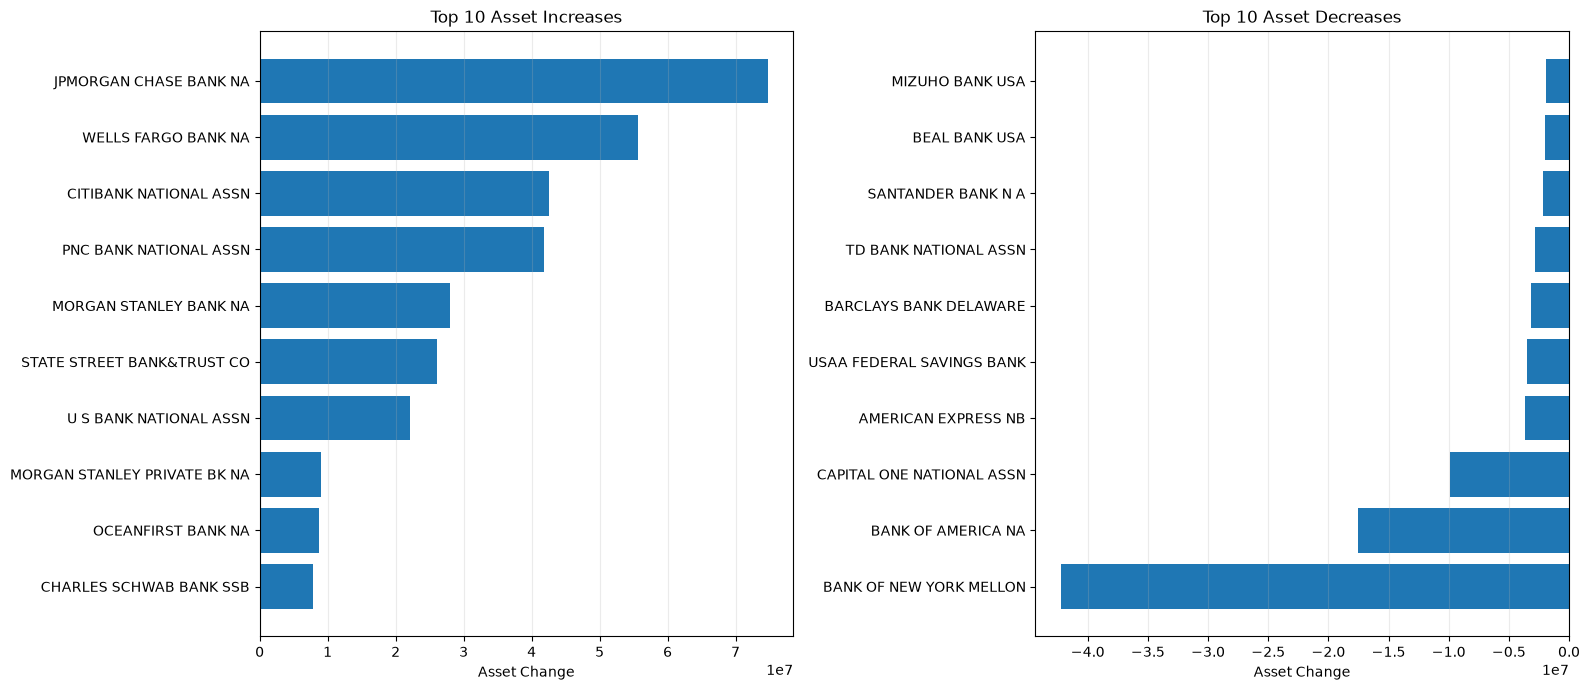

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Largest increases
increase_plot = top_asset_increases.sort_values("ASSET_CHANGE")

axes[0].barh(
    increase_plot["NAME"],
    increase_plot["ASSET_CHANGE"]
)

axes[0].set_title("Top 10 Asset Increases")
axes[0].set_xlabel("Asset Change")
axes[0].grid(axis="x", alpha=0.25)

# Largest decreases
decrease_plot = top_asset_decreases.sort_values("ASSET_CHANGE")

axes[1].barh(
    decrease_plot["NAME"],
    decrease_plot["ASSET_CHANGE"]
)

axes[1].set_title("Top 10 Asset Decreases")
axes[1].set_xlabel("Asset Change")
axes[1].grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

### Interpretation of Asset Movements

- JPMorgan Chase Bank NA recorded the largest absolute asset increase, followed by Wells Fargo Bank NA.
- Bank of New York Mellon recorded the largest absolute asset decrease.
- Asset movements were concentrated among a relatively small number of major institutions.
- The magnitude of the largest increases and decreases varies considerably.

The results highlight substantial differences in quarterly asset movements across institutions. Further investigation would be required to identify the underlying reasons for these changes.

In [17]:
# Top 10 institutions with the largest net income increases
top_income_increases = comparison.sort_values(
    by="NETINC_CHANGE",
    ascending=False
)[
    ["CERT", "NAME", "NETINC_Q1", "NETINC_Q2", "NETINC_CHANGE"]
].head(10)

# Top 10 institutions with the largest net income decreases
top_income_decreases = comparison.sort_values(
    by="NETINC_CHANGE",
    ascending=True
)[
    ["CERT", "NAME", "NETINC_Q1", "NETINC_Q2", "NETINC_CHANGE"]
].head(10)

print("Top 10 Net Income Increases")
display(top_income_increases)

print("Top 10 Net Income Decreases")
display(top_income_decreases)

Top 10 Net Income Increases


,CERT,NAME,NETINC_Q1,NETINC_Q2,NETINC_CHANGE
102,628,JPMORGAN CHASE BANK NA,13974000.0,31335000.0,17361000.0
479,3510,BANK OF AMERICA NA,7417000.0,14947000.0,7530000.0
480,3511,WELLS FARGO BANK NA,5961000.0,12808000.0,6847000.0
941,7213,CITIBANK NATIONAL ASSN,5011000.0,10118000.0,5107000.0
612,4297,CAPITAL ONE NATIONAL ASSN,2317000.0,5552000.0,3235000.0
3532,33124,GOLDMAN SACHS BANK USA,1959000.0,4333000.0,2374000.0
890,6548,U S BANK NATIONAL ASSN,1991808.0,4225746.0,2233938.0
881,6384,PNC BANK NATIONAL ASSN,1870675.0,3954707.0,2084032.0
3069,27471,AMERICAN EXPRESS NB,2002501.0,3959779.0,1957278.0
1275,9846,TRUIST BANK,1573000.0,3155000.0,1582000.0


Top 10 Net Income Decreases


,CERT,NAME,NETINC_Q1,NETINC_Q2,NETINC_CHANGE
2236,16571,BMO BANK NATIONAL ASSN,732963.0,184424.0,-548539.0
2883,24045,BANC OF CALIFORNIA,80722.0,-152251.0,-232973.0
4083,58629,STELLAR BANK,31651.0,-33329.0,-64980.0
3633,34403,COASTAL COMMUNITY BANK,12420.0,-29127.0,-41547.0
3718,34997,BAYFIRST NATIONAL BANK,-5708.0,-38133.0,-32425.0
4156,59190,VARO BANK NATIONAL ASSN,-23147.0,-46573.0,-23426.0
3795,35541,BCB COMMUNITY BANK,5742.0,-8034.0,-13776.0
3982,58088,SOUTHPOINT BANK,-973.0,-12421.0,-11448.0
3147,28380,ADIRONDACK BANK,466.0,-10439.0,-10905.0
4202,59378,EREBOR BANK N A,-6009.0,-16322.0,-10313.0


In [18]:
comparison.loc[
    comparison["CERT"] == 59378,
    ["CERT", "NAME", "NETINC_Q1", "NETINC_Q2", "NETINC_CHANGE"]
]

,CERT,NAME,NETINC_Q1,NETINC_Q2,NETINC_CHANGE
4202,59378,EREBOR BANK N A,-6009.0,-16322.0,-10313.0


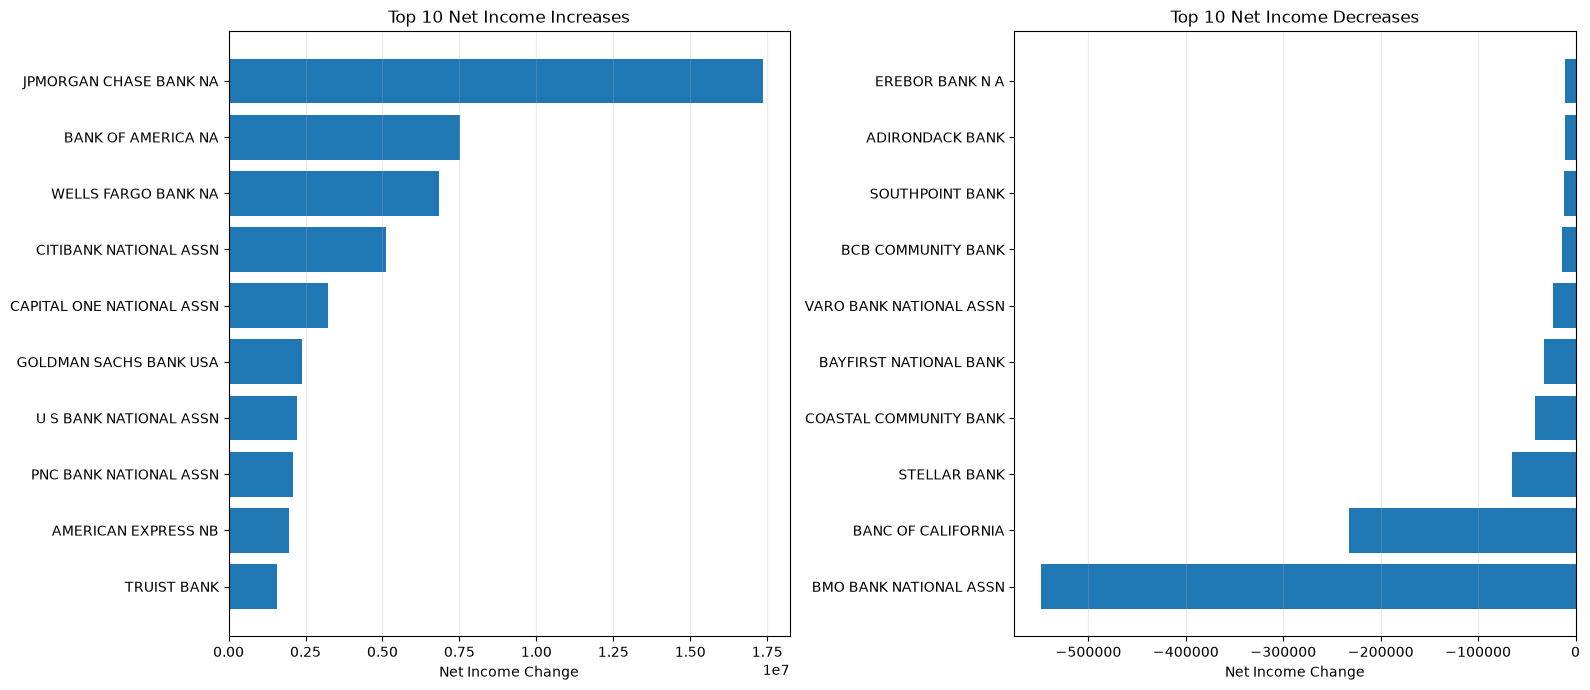

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Largest increases
income_increase_plot = top_income_increases.sort_values(
    "NETINC_CHANGE"
)

axes[0].barh(
    income_increase_plot["NAME"],
    income_increase_plot["NETINC_CHANGE"]
)

axes[0].set_title("Top 10 Net Income Increases")
axes[0].set_xlabel("Net Income Change")
axes[0].grid(axis="x", alpha=0.25)

# Largest decreases
income_decrease_plot = top_income_decreases.sort_values(
    "NETINC_CHANGE"
)

axes[1].barh(
    income_decrease_plot["NAME"],
    income_decrease_plot["NETINC_CHANGE"]
)

axes[1].set_title("Top 10 Net Income Decreases")
axes[1].set_xlabel("Net Income Change")
axes[1].grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

### Interpretation of Net Income Movements

- JPMorgan Chase Bank NA recorded the largest increase in net income, followed by Bank of America NA and Wells Fargo Bank NA.
- BMO Bank National Association recorded the largest decrease, followed by Banc of California.
- The largest increases were concentrated among major banking institutions.
- Several institutions experienced a transition from positive to negative net income, while others reported further decreases in already negative net income.
- The magnitude of the largest net income increases was substantially greater than that of the largest decreases.

These findings highlight differences in quarterly net income movements across institutions. They do not independently establish the reasons behind the changes or indicate long-term profitability trends.

## 10. Return on Assets (ROA) Analysis

This section examines changes in Return on Assets (ROA) across matched institutions between Q1 and Q2 2026.

It identifies institutions with the largest increases and decreases in ROA and explores the distribution of quarterly changes.

The analysis uses reported ROA values and does not assume that changes necessarily indicate long-term improvements or deterioration in financial performance.

In [20]:
# Top 10 institutions with the largest ROA increases
top_roa_increases = comparison.sort_values(
    by="ROA_CHANGE",
    ascending=False
)[
    ["CERT", "NAME", "ROA_Q1", "ROA_Q2", "ROA_CHANGE"]
].head(10)

# Top 10 institutions with the largest ROA decreases
top_roa_decreases = comparison.sort_values(
    by="ROA_CHANGE",
    ascending=True
)[
    ["CERT", "NAME", "ROA_Q1", "ROA_Q2", "ROA_CHANGE"]
].head(10)

print("Top 10 ROA Increases")
display(top_roa_increases)

print("Top 10 ROA Decreases")
display(top_roa_decreases)

Top 10 ROA Increases


,CERT,NAME,ROA_Q1,ROA_Q2,ROA_CHANGE
3664,34619,ITS BANK,4.051559,61.629120,57.577561
3384,30357,STREATOR HOME SAVINGS BANK,-38.543084,-18.930062,19.613022
2427,17878,BANK OF LOUISIANA,0.093228,16.117506,16.024278
4200,59365,GENERATIONS COMMUNITY BANK,-38.540348,-22.639655,15.900693
3833,57160,NATIONAL ADVISORS TRUST CO,11.291846,21.174461,9.882615
1081,8681,LAMONT BANK OF ST JOHN,-12.106241,-6.225063,5.881178
3578,33855,CREDIT FIRST NATIONAL ASSN,16.735685,22.537810,5.802125
2483,18227,STAFFORD SAVINGS BANK,2.500781,8.231186,5.730405
1825,13959,CBW BANK,-3.961114,1.695167,5.656281
3932,57833,BEAL BANK USA,2.545632,8.194962,5.649329


Top 10 ROA Decreases


,CERT,NAME,ROA_Q1,ROA_Q2,ROA_CHANGE
3545,33492,CRESCENT BANK,19.630606,8.336081,-11.294525
3788,35510,DAVIDSON TRUST CO,8.493184,3.498450,-4.994733
2874,23864,SUMMIT BANK,1.059433,-3.452837,-4.512270
3718,34997,BAYFIRST NATIONAL BANK,-1.836303,-6.315341,-4.479038
2941,25803,HATCH BANK,4.766123,0.301887,-4.464237
4078,58596,CARTER BANK&TRUST,7.125861,3.663495,-3.462366
2351,17388,M C BANK&TRUST CO,0.842198,-2.562093,-3.404291
3024,26816,LIBERTY BANK INC,-8.543384,-11.624441,-3.081057
3942,57884,PARAMOUNT BANK,-0.913740,-3.926171,-3.012431
2930,25620,CREDIT ONE BANK NA,28.308559,25.346352,-2.962207


In [21]:
comparison.loc[
    comparison["CERT"] == 25620,
    ["CERT", "NAME", "ROA_Q1", "ROA_Q2", "ROA_CHANGE"]
]

,CERT,NAME,ROA_Q1,ROA_Q2,ROA_CHANGE
2930,25620,CREDIT ONE BANK NA,28.308559,25.346352,-2.962207


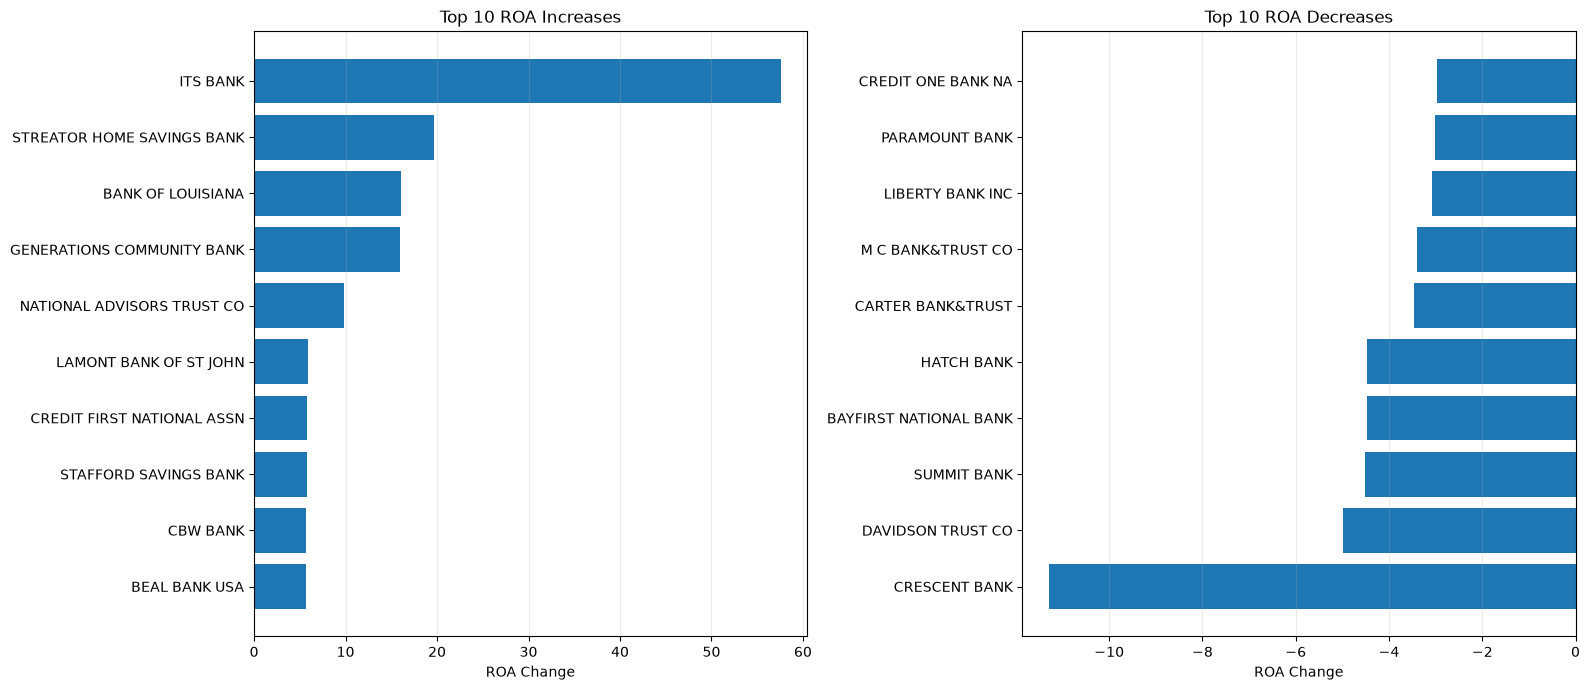

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Largest ROA increases
roa_increase_plot = top_roa_increases.sort_values("ROA_CHANGE")

axes[0].barh(
    roa_increase_plot["NAME"],
    roa_increase_plot["ROA_CHANGE"]
)

axes[0].set_title("Top 10 ROA Increases")
axes[0].set_xlabel("ROA Change")
axes[0].grid(axis="x", alpha=0.25)

# Largest ROA decreases
roa_decrease_plot = top_roa_decreases.sort_values("ROA_CHANGE")

axes[1].barh(
    roa_decrease_plot["NAME"],
    roa_decrease_plot["ROA_CHANGE"]
)

axes[1].set_title("Top 10 ROA Decreases")
axes[1].set_xlabel("ROA Change")
axes[1].grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

### Interpretation of ROA Movements

- ITS Bank recorded the largest increase in ROA, followed by Streator Home Savings Bank and Bank of Louisiana.
- Crescent Bank recorded the largest decrease, followed by Davidson Trust Co.
- Some institutions experienced improvements in ROA but continued to report negative values.
- Summit Bank moved from positive ROA in Q1 to negative ROA in Q2.
- The magnitude of ROA changes varied considerably across institutions.

These findings highlight differences in reported asset profitability indicators between the two quarters. Unusually large movements require further investigation before drawing conclusions about underlying financial performance.

## 11. Return on Equity (ROE) Analysis

This section examines changes in Return on Equity (ROE) across matched institutions between Q1 and Q2 2026.

It identifies institutions with the largest increases and decreases in ROE and explores differences in reported equity-based profitability indicators.

In [23]:
# Top 10 institutions with the largest ROE increases
top_roe_increases = comparison.sort_values(
    by="ROE_CHANGE",
    ascending=False
)[
    ["CERT", "NAME", "ROE_Q1", "ROE_Q2", "ROE_CHANGE"]
].head(10)

# Top 10 institutions with the largest ROE decreases
top_roe_decreases = comparison.sort_values(
    by="ROE_CHANGE",
    ascending=True
)[
    ["CERT", "NAME", "ROE_Q1", "ROE_Q2", "ROE_CHANGE"]
].head(10)

print("Top 10 ROE Increases")
display(top_roe_increases)

print("Top 10 ROE Decreases")
display(top_roe_decreases)

Top 10 ROE Increases


,CERT,NAME,ROE_Q1,ROE_Q2,ROE_CHANGE
1081,8681,LAMONT BANK OF ST JOHN,-385.62,-228.84,156.78
2427,17878,BANK OF LOUISIANA,0.86,122.62,121.76
3384,30357,STREATOR HOME SAVINGS BANK,-156.93,-80.79,76.14
3664,34619,ITS BANK,4.14,64.93,60.79
3570,33802,TIOGA-FRANKLIN SAVINGS BANK,-161.26,-121.19,40.07
2534,18618,SMBC MANUBANK,-63.90,-32.51,31.39
3954,57931,ANCHOR BANK,12.57,41.85,29.28
1909,14574,ODIN STATE BANK,-30.66,-1.39,29.27
3932,57833,BEAL BANK USA,12.33,37.98,25.65
3851,57336,DRAKE BANK,-43.31,-17.71,25.60


Top 10 ROE Decreases


,CERT,NAME,ROE_Q1,ROE_Q2,ROE_CHANGE
488,3639,FIRST NATIONAL BANK&TRUST CO,211.54,72.37,-139.17
2338,17280,BANK OF TIOGA,194.71,83.08,-111.63
3545,33492,CRESCENT BANK,141.04,59.15,-81.89
2917,25054,SUMMIT NATIONAL BANK,-30.55,-101.58,-71.03
341,2359,MAUCH CHUNK TRUST CO,103.05,40.48,-62.57
3718,34997,BAYFIRST NATIONAL BANK,-26.20,-79.98,-53.78
1524,11539,ENTERPRISE BANK OF SC,123.01,80.70,-42.31
1947,14812,TS BANK,83.46,41.81,-41.65
4078,58596,CARTER BANK&TRUST,77.85,37.13,-40.72
3147,28380,ADIRONDACK BANK,2.52,-29.99,-32.51


### Interpretation of ROE Movements

- Lamont Bank of St John recorded the largest numerical increase in ROE, followed by Bank of Louisiana and Streator Home Savings Bank.
- First National Bank & Trust Co recorded the largest decrease, followed by Bank of Tioga and Crescent Bank.
- Some institutions experienced improvements while continuing to report negative ROE values.
- Other institutions recorded decreases while maintaining positive ROE values.
- The magnitude of ROE changes varied considerably across institutions, with several unusually large movements.

These observations highlight differences in reported equity-based profitability indicators between Q1 and Q2 2026. Extreme movements should be interpreted cautiously and investigated further before drawing conclusions about financial performance.

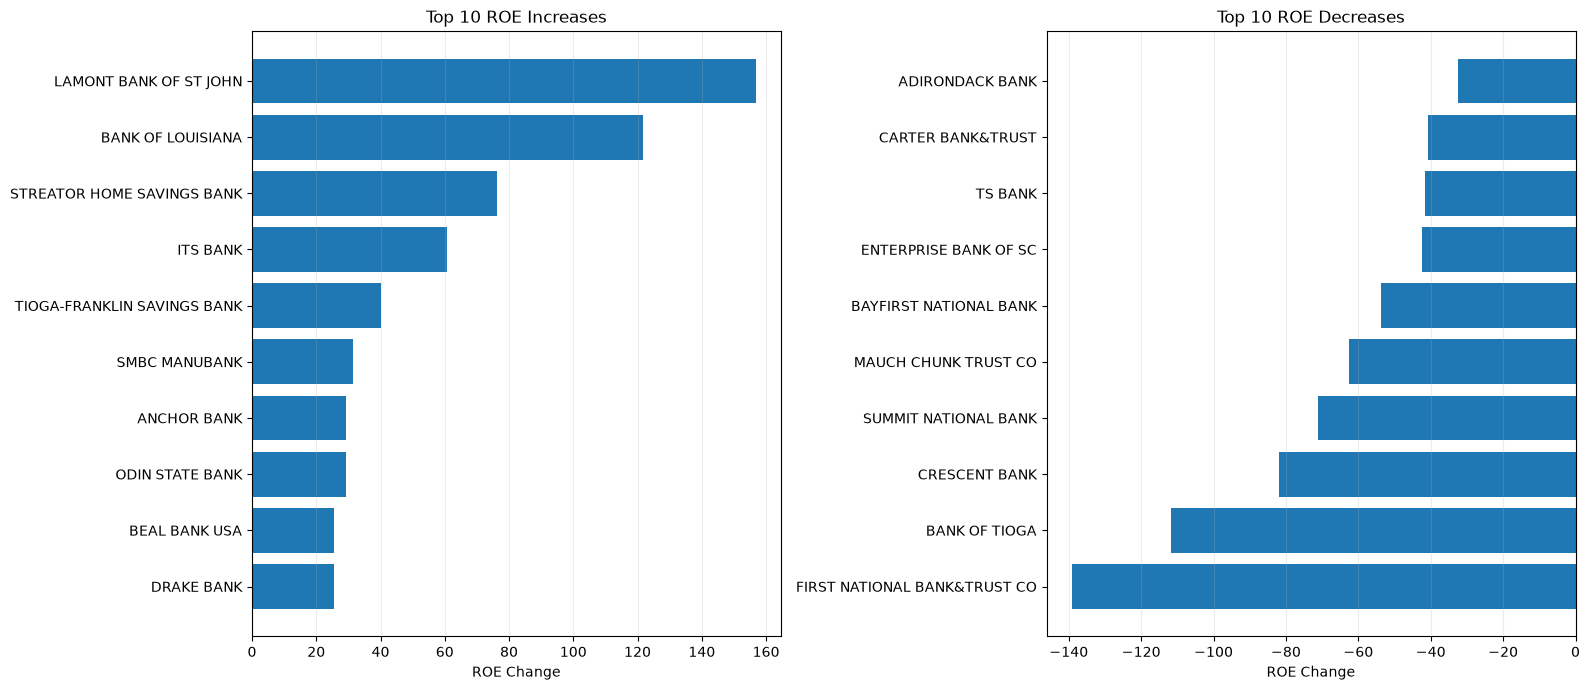

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Largest ROE increases
roe_increase_plot = top_roe_increases.sort_values("ROE_CHANGE")

axes[0].barh(
    roe_increase_plot["NAME"],
    roe_increase_plot["ROE_CHANGE"]
)

axes[0].set_title("Top 10 ROE Increases")
axes[0].set_xlabel("ROE Change")
axes[0].grid(axis="x", alpha=0.25)

# Largest ROE decreases
roe_decrease_plot = top_roe_decreases.sort_values("ROE_CHANGE")

axes[1].barh(
    roe_decrease_plot["NAME"],
    roe_decrease_plot["ROE_CHANGE"]
)

axes[1].set_title("Top 10 ROE Decreases")
axes[1].set_xlabel("ROE Change")
axes[1].grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

### Interpretation of ROE Movements

- Lamont Bank of St John recorded the largest numerical increase in ROE, followed by Bank of Louisiana and Streator Home Savings Bank.
- First National Bank & Trust Co recorded the largest decrease, followed by Bank of Tioga and Crescent Bank.
- Some institutions improved their ROE while continuing to report negative values.
- Other institutions experienced decreases while maintaining positive ROE values.
- The wide range of changes indicates considerable variation in reported ROE movements across institutions.

These findings describe changes in reported ROE values between Q1 and Q2 2026. Extreme movements require further investigation before conclusions about underlying financial performance can be drawn.

## 12. Overall Financial Comparison Between Q1 and Q2 2026

This section summarizes the changes in major financial indicators across matched institutions between Q1 and Q2 2026.

The comparison brings together balance-sheet measures and profitability indicators to identify broader patterns in the quarterly financial data.

### 12.1 Summary of Financial Changes

This analysis summarizes the direction and magnitude of changes in major financial indicators between Q1 and Q2 2026.

The median change represents the middle value of the observed changes, while the mean change represents their average. The number of institutions with increases, decreases, and unchanged values is also examined.

In [25]:
# Financial metrics to summarize
summary_metrics = [
    "ASSET", "LIAB", "DEP", "EQ",
    "NETINC", "ROA", "ROE"
]

summary_rows = []

for metric in summary_metrics:

    changes = comparison[f"{metric}_CHANGE"].dropna()

    summary_rows.append({
        "Metric": metric,
        "Institutions Analyzed": len(changes),
        "Increased": (changes > 0).sum(),
        "Decreased": (changes < 0).sum(),
        "Unchanged": (changes == 0).sum(),
        "Median Change": changes.median(),
        "Mean Change": changes.mean()
    })

overall_summary = pd.DataFrame(summary_rows)

display(overall_summary.round(2))

,Metric,Institutions Analyzed,Increased,Decreased,Unchanged,Median Change,Mean Change
0,ASSET,4243,2473,1769,1,1406.00,94098.71
1,LIAB,4243,2296,1946,1,691.00,90592.99
2,DEP,4243,2161,2062,20,120.00,57389.60
3,EQ,4234,3640,590,4,750.50,3526.79
4,NETINC,4234,4056,178,0,1194.50,21302.89
5,ROA,4243,2855,1379,9,0.04,0.07
6,ROE,4233,2724,1485,24,0.34,0.33


### Interpretation of Overall Financial Changes

- A majority of matched institutions recorded increases in assets, liabilities, ROA, and ROE.
- Equity increased in approximately 86% of the institutions analyzed.
- Net income recorded the highest proportion of increases, with approximately 96% of institutions showing positive changes.
- Changes in deposits were relatively balanced between increases and decreases.
- For assets, liabilities, equity, and net income, mean changes were considerably higher than median changes, suggesting that large movements among some institutions influenced the averages.
- The median provides additional context because it is less affected by unusually large observations.

Overall, the comparison reveals widespread increases in several reported financial indicators between Q1 and Q2 2026. However, these findings describe quarterly changes and should not automatically be interpreted as evidence of long-term financial strength or improved financial health.

In [26]:
# Calculate percentage distribution of changes
direction_columns = ["Increased", "Decreased", "Unchanged"]

direction_percentages = overall_summary[
    ["Metric", "Institutions Analyzed"] + direction_columns
].copy()

for column in direction_columns:
    direction_percentages[column] = (
        direction_percentages[column]
        / direction_percentages["Institutions Analyzed"]
        * 100
    )

display(direction_percentages.round(2))

,Metric,Institutions Analyzed,Increased,Decreased,Unchanged
0,ASSET,4243,58.28,41.69,0.02
1,LIAB,4243,54.11,45.86,0.02
2,DEP,4243,50.93,48.60,0.47
3,EQ,4234,85.97,13.93,0.09
4,NETINC,4234,95.80,4.20,0.00
5,ROA,4243,67.29,32.50,0.21
6,ROE,4233,64.35,35.08,0.57


## 12.2 Asset Growth vs Deposit Growth

### Objective
Examine the relationship between changes in total assets and customer deposits across matched banking institutions between Q1 and Q2 2026.

### Why This Analysis Matters
Assets represent the resources held by a bank, while deposits are an important source of funding. Comparing their growth helps us understand whether banks expanding their balance sheets are also experiencing deposit growth.

### Analysis Approach
- Calculate asset growth percentages.
- Calculate deposit growth percentages.
- Measure their relationship using Pearson and Spearman correlation.
- Classify institutions based on their asset and deposit growth patterns.
- Examine the distribution of growth rates.

**Note:** Asset growth alongside declining deposits does not automatically indicate financial distress.

In [27]:
import pandas as pd
import numpy as np

# Prepare analysis dataset
growth_analysis = comparison[
    [
        "CERT", "NAME",
        "ASSET_Q1", "ASSET_Q2", "ASSET_CHANGE",
        "DEP_Q1", "DEP_Q2", "DEP_CHANGE"
    ]
].copy()

# Calculate asset growth percentage
growth_analysis["ASSET_GROWTH_PCT"] = np.where(
    growth_analysis["ASSET_Q1"] > 0,
    (growth_analysis["ASSET_CHANGE"] /
     growth_analysis["ASSET_Q1"]) * 100,
    np.nan
)

# Calculate deposit growth percentage
growth_analysis["DEP_GROWTH_PCT"] = np.where(
    growth_analysis["DEP_Q1"] > 0,
    (growth_analysis["DEP_CHANGE"] /
     growth_analysis["DEP_Q1"]) * 100,
    np.nan
)

# Keep valid observations
valid_growth = growth_analysis.dropna(
    subset=["ASSET_GROWTH_PCT", "DEP_GROWTH_PCT"]
).copy()

# Calculate Pearson and Spearman correlations
pearson_corr = valid_growth[
    ["ASSET_GROWTH_PCT", "DEP_GROWTH_PCT"]
].corr(method="pearson").iloc[0, 1]

spearman_corr = valid_growth[
    ["ASSET_GROWTH_PCT", "DEP_GROWTH_PCT"]
].corr(method="spearman").iloc[0, 1]

# Classify growth patterns
conditions = [
    (valid_growth["ASSET_GROWTH_PCT"] > 0) &
    (valid_growth["DEP_GROWTH_PCT"] > 0),

    (valid_growth["ASSET_GROWTH_PCT"] > 0) &
    (valid_growth["DEP_GROWTH_PCT"] < 0),

    (valid_growth["ASSET_GROWTH_PCT"] < 0) &
    (valid_growth["DEP_GROWTH_PCT"] > 0),

    (valid_growth["ASSET_GROWTH_PCT"] < 0) &
    (valid_growth["DEP_GROWTH_PCT"] < 0)
]

labels = [
    "Both Increased",
    "Assets Increased, Deposits Decreased",
    "Assets Decreased, Deposits Increased",
    "Both Decreased"
]

valid_growth["GROWTH_PATTERN"] = np.select(
    conditions,
    labels,
    default="One or Both Unchanged"
)

# Display results
print("ASSET GROWTH VS DEPOSIT GROWTH")
print("=" * 45)

print("Total matched institutions:", len(growth_analysis))
print("Valid institutions analyzed:", len(valid_growth))

print("\nCORRELATION ANALYSIS")
print("-" * 30)
print(f"Pearson Correlation:  {pearson_corr:.4f}")
print(f"Spearman Correlation: {spearman_corr:.4f}")

print("\nGROWTH PATTERN DISTRIBUTION")
print("-" * 30)
print(valid_growth["GROWTH_PATTERN"].value_counts())

print("\nGROWTH PATTERN PERCENTAGES")
print("-" * 30)
print(
    (valid_growth["GROWTH_PATTERN"]
     .value_counts(normalize=True) * 100).round(2)
)

print("\nGROWTH RATE SUMMARY (%)")
print("-" * 30)
print(
    valid_growth[
        ["ASSET_GROWTH_PCT", "DEP_GROWTH_PCT"]
    ].describe().round(2)
)

ASSET GROWTH VS DEPOSIT GROWTH
Total matched institutions: 4243
Valid institutions analyzed: 4243

CORRELATION ANALYSIS
------------------------------
Pearson Correlation:  0.0660
Spearman Correlation: 0.8354

GROWTH PATTERN DISTRIBUTION
------------------------------
GROWTH_PATTERN
Both Increased                          2006
Both Decreased                          1607
Assets Increased, Deposits Decreased     454
Assets Decreased, Deposits Increased     155
One or Both Unchanged                     21
Name: count, dtype: int64

GROWTH PATTERN PERCENTAGES
------------------------------
GROWTH_PATTERN
Both Increased                          47.28
Both Decreased                          37.87
Assets Increased, Deposits Decreased    10.70
Assets Decreased, Deposits Increased     3.65
One or Both Unchanged                    0.49
Name: proportion, dtype: float64

GROWTH RATE SUMMARY (%)
------------------------------
       ASSET_GROWTH_PCT  DEP_GROWTH_PCT
count           4243.00         

### 12.2.1 Correlation Sensitivity Analysis

The initial analysis revealed a substantial difference between Pearson and Spearman correlation.

To investigate this difference, the analysis examines extreme growth observations and compares Pearson correlation before and after winsorizing the growth rates at the 1st and 99th percentiles.

Winsorization limits the influence of extreme values without deleting the observations.

This helps determine whether the weak Pearson correlation is influenced by unusually large growth rates.

In [28]:
# Correlation sensitivity analysis

print("CORRELATION SENSITIVITY ANALYSIS")
print("=" * 45)

# Identify extreme growth observations
print("\nEXTREME ASSET GROWTH")
print("-" * 30)

print(
    valid_growth.nlargest(5, "ASSET_GROWTH_PCT")[
        ["CERT", "NAME", "ASSET_GROWTH_PCT", "DEP_GROWTH_PCT"]
    ].to_string(index=False)
)

print("\nEXTREME DEPOSIT GROWTH")
print("-" * 30)

print(
    valid_growth.nlargest(5, "DEP_GROWTH_PCT")[
        ["CERT", "NAME", "ASSET_GROWTH_PCT", "DEP_GROWTH_PCT"]
    ].to_string(index=False)
)

# Winsorize at 1st and 99th percentiles
winsorized_growth = valid_growth[
    ["ASSET_GROWTH_PCT", "DEP_GROWTH_PCT"]
].copy()

for column in winsorized_growth.columns:
    lower = winsorized_growth[column].quantile(0.01)
    upper = winsorized_growth[column].quantile(0.99)

    winsorized_growth[column] = winsorized_growth[column].clip(
        lower=lower,
        upper=upper
    )

# Calculate correlations after winsorization
pearson_winsorized = winsorized_growth.corr(
    method="pearson"
).iloc[0, 1]

spearman_winsorized = winsorized_growth.corr(
    method="spearman"
).iloc[0, 1]

print("\nCORRELATION COMPARISON")
print("-" * 30)

print(f"Original Pearson:       {pearson_corr:.4f}")
print(f"Winsorized Pearson:     {pearson_winsorized:.4f}")
print(f"Original Spearman:      {spearman_corr:.4f}")
print(f"Winsorized Spearman:    {spearman_winsorized:.4f}")

CORRELATION SENSITIVITY ANALYSIS

EXTREME ASSET GROWTH
------------------------------
 CERT                  NAME  ASSET_GROWTH_PCT  DEP_GROWTH_PCT
18463         HERITAGE BANK       1078.157729       72.030522
59378       EREBOR BANK N A        173.857409      269.588297
59345      FIVE RIVERS BANK        106.005959      480.812325
 4752   FIRST SECURITY BANK         93.300259       86.269511
 5105 B2 BANK NATIONAL ASSN         84.855133      104.052593

EXTREME DEPOSIT GROWTH
------------------------------
 CERT                       NAME  ASSET_GROWTH_PCT  DEP_GROWTH_PCT
59365 GENERATIONS COMMUNITY BANK         18.571812     5385.294118
59345           FIVE RIVERS BANK        106.005959      480.812325
59378            EREBOR BANK N A        173.857409      269.588297
59369 LIBERTY BANK OF NEW JERSEY         52.068047      172.687593
23472 BANK OF NY MELLON TR CO NA         -1.375189      108.496732

CORRELATION COMPARISON
------------------------------
Original Pearson:       0.0660

### Interpretation of Asset Growth vs Deposit Growth

The analysis covered 4,243 matched banking institutions.

- 47.28% of institutions experienced increases in both assets and deposits.
- 37.87% experienced decreases in both indicators.
- 10.70% recorded asset growth despite declining deposits.
- 3.65% experienced declining assets alongside increasing deposits.

The original Pearson correlation was 0.0660, while the Spearman correlation was 0.8354.

A sensitivity analysis using winsorization at the 1st and 99th percentiles increased Pearson correlation to 0.8885. Spearman correlation remained unchanged at 0.8354.

This substantial difference indicates that extreme growth observations strongly influence the original Pearson correlation. The rank-based relationship, however, remains strongly positive.

Overall, asset and deposit growth generally show a positive relationship across institutions, although individual banks exhibit different growth patterns.

**Conclusion:** Extreme observations must be considered when interpreting financial growth relationships. Asset growth without deposit growth should be investigated further, but it does not independently establish financial weakness.

## 12.3 Equity-to-Assets Ratio Analysis

### Objective
Analyze changes in the equity-to-assets ratio across matched banking institutions between Q1 and Q2 2026.

### Why This Analysis Matters
The equity-to-assets ratio indicates the proportion of a bank's total assets supported by its reported equity.

A higher ratio generally indicates a larger equity buffer relative to assets, while a declining ratio may indicate that assets are growing faster than equity.

### Analysis Approach
- Calculate the equity-to-assets ratio for Q1 and Q2.
- Calculate the change in the ratio in percentage points.
- Identify institutions with increasing and decreasing ratios.
- Compare the distribution across both quarters.
- Identify institutions reporting negative equity.

**Note:** This is a simplified balance-sheet indicator and should not be treated as a regulatory capital adequacy ratio.

In [29]:
# 12.3 Equity-to-Assets Ratio Analysis

equity_analysis = comparison[
    [
        "CERT", "NAME",
        "ASSET_Q1", "ASSET_Q2",
        "EQ_Q1", "EQ_Q2"
    ]
].copy()

# Calculate equity-to-assets ratio for Q1
equity_analysis["EQUITY_ASSET_Q1"] = np.where(
    equity_analysis["ASSET_Q1"] > 0,
    (equity_analysis["EQ_Q1"] /
     equity_analysis["ASSET_Q1"]) * 100,
    np.nan
)

# Calculate equity-to-assets ratio for Q2
equity_analysis["EQUITY_ASSET_Q2"] = np.where(
    equity_analysis["ASSET_Q2"] > 0,
    (equity_analysis["EQ_Q2"] /
     equity_analysis["ASSET_Q2"]) * 100,
    np.nan
)

# Calculate change in percentage points
equity_analysis["RATIO_CHANGE"] = (
    equity_analysis["EQUITY_ASSET_Q2"] -
    equity_analysis["EQUITY_ASSET_Q1"]
)

# Retain valid observations
valid_equity = equity_analysis.dropna(
    subset=["EQUITY_ASSET_Q1", "EQUITY_ASSET_Q2"]
).copy()

# Classify ratio movement
valid_equity["RATIO_TREND"] = np.select(
    [
        valid_equity["RATIO_CHANGE"] > 0,
        valid_equity["RATIO_CHANGE"] < 0
    ],
    [
        "Increased",
        "Decreased"
    ],
    default="Unchanged"
)

# Identify negative equity institutions
negative_equity = equity_analysis[
    (equity_analysis["EQ_Q1"] < 0) |
    (equity_analysis["EQ_Q2"] < 0)
].copy()

# Display results
print("EQUITY-TO-ASSETS RATIO ANALYSIS")
print("=" * 45)

print("Total matched institutions:", len(equity_analysis))
print("Valid institutions analyzed:", len(valid_equity))

print("\nRATIO SUMMARY")
print("-" * 30)

print(
    valid_equity[
        ["EQUITY_ASSET_Q1", "EQUITY_ASSET_Q2", "RATIO_CHANGE"]
    ].describe().round(2)
)

print("\nRATIO MOVEMENT")
print("-" * 30)

print(valid_equity["RATIO_TREND"].value_counts())

print("\nRATIO MOVEMENT PERCENTAGES")
print("-" * 30)

print(
    (valid_equity["RATIO_TREND"]
     .value_counts(normalize=True) * 100).round(2)
)

print("\nNEGATIVE EQUITY OBSERVATIONS")
print("-" * 30)

print("Institutions with negative equity in Q1 or Q2:",
      len(negative_equity))

print("Negative equity in Q1:",
      (equity_analysis["EQ_Q1"] < 0).sum())

print("Negative equity in Q2:",
      (equity_analysis["EQ_Q2"] < 0).sum())

EQUITY-TO-ASSETS RATIO ANALYSIS
Total matched institutions: 4243
Valid institutions analyzed: 4234

RATIO SUMMARY
------------------------------
       EQUITY_ASSET_Q1  EQUITY_ASSET_Q2  RATIO_CHANGE
count          4234.00          4234.00       4234.00
mean             11.74            11.91          0.16
std               7.37             7.35          1.94
min              -1.15            -1.59        -40.09
25%               8.91             9.06         -0.07
50%              10.38            10.56          0.16
75%              12.52            12.72          0.40
max              99.15            99.28         82.84

RATIO MOVEMENT
------------------------------
RATIO_TREND
Increased    2893
Decreased    1341
Name: count, dtype: int64

RATIO MOVEMENT PERCENTAGES
------------------------------
RATIO_TREND
Increased    68.33
Decreased    31.67
Name: proportion, dtype: float64

NEGATIVE EQUITY OBSERVATIONS
------------------------------
Institutions with negative equity in Q1 or Q2

### Interpretation of Equity-to-Assets Ratio

The equity-to-assets ratio was calculated for 4,234 matched institutions with valid equity and asset values in both quarters.

The mean ratio increased from 11.74% in Q1 2026 to 11.91% in Q2 2026, while the median increased from 10.38% to 10.56%.

Out of the 4,234 institutions:
- 2,893 (68.31%) experienced an increase in the ratio.
- 1,341 (31.69%) experienced a decrease.

The median ratio change was positive at 0.16 percentage points, indicating a modest improvement in equity relative to assets for the typical institution.

One institution reported negative equity in both quarters.

Overall, the results indicate that a majority of institutions experienced an improvement in their equity-to-assets ratio. However, this simplified indicator should not be confused with regulatory capital adequacy measures or used independently to determine financial stability.

## 12.4 Liability-to-Assets Ratio Analysis

### Objective
Examine the proportion of total assets financed through liabilities and analyze how this relationship changed between Q1 and Q2 2026.

### Why This Analysis Matters
Liabilities represent the financial obligations of a bank. Comparing liabilities with total assets helps assess the composition of a bank's balance sheet.

A higher liability-to-assets ratio indicates that a larger proportion of assets is financed through liabilities.

### Analysis Approach
- Calculate the liability-to-assets ratio for Q1 and Q2.
- Calculate the change in percentage points.
- Identify institutions with increasing and decreasing ratios.
- Compare the distribution across both quarters.
- Identify institutions with unusually high liability-to-assets ratios.

**Note:** A high ratio is not automatically a sign of financial distress. Banks normally operate with substantial liabilities, including customer deposits.

In [30]:
# 12.4 Liability-to-Assets Ratio Analysis

liability_analysis = comparison[
    [
        "CERT", "NAME",
        "ASSET_Q1", "ASSET_Q2",
        "LIAB_Q1", "LIAB_Q2"
    ]
].copy()

# Calculate liability-to-assets ratio for Q1
liability_analysis["LIAB_ASSET_Q1"] = np.where(
    liability_analysis["ASSET_Q1"] > 0,
    (liability_analysis["LIAB_Q1"] /
     liability_analysis["ASSET_Q1"]) * 100,
    np.nan
)

# Calculate liability-to-assets ratio for Q2
liability_analysis["LIAB_ASSET_Q2"] = np.where(
    liability_analysis["ASSET_Q2"] > 0,
    (liability_analysis["LIAB_Q2"] /
     liability_analysis["ASSET_Q2"]) * 100,
    np.nan
)

# Calculate change in percentage points
liability_analysis["RATIO_CHANGE"] = (
    liability_analysis["LIAB_ASSET_Q2"] -
    liability_analysis["LIAB_ASSET_Q1"]
)

# Keep valid observations
valid_liability = liability_analysis.dropna(
    subset=["LIAB_ASSET_Q1", "LIAB_ASSET_Q2"]
).copy()

# Classify ratio movement
valid_liability["RATIO_TREND"] = np.select(
    [
        valid_liability["RATIO_CHANGE"] > 0,
        valid_liability["RATIO_CHANGE"] < 0
    ],
    [
        "Increased",
        "Decreased"
    ],
    default="Unchanged"
)

# Display summary
print("LIABILITY-TO-ASSETS RATIO ANALYSIS")
print("=" * 45)

print("Total matched institutions:", len(liability_analysis))
print("Valid institutions analyzed:", len(valid_liability))

print("\nRATIO SUMMARY")
print("-" * 30)

print(
    valid_liability[
        ["LIAB_ASSET_Q1", "LIAB_ASSET_Q2", "RATIO_CHANGE"]
    ].describe().round(2)
)

print("\nRATIO MOVEMENT")
print("-" * 30)

print(valid_liability["RATIO_TREND"].value_counts())

print("\nRATIO MOVEMENT PERCENTAGES")
print("-" * 30)

print(
    (valid_liability["RATIO_TREND"]
     .value_counts(normalize=True) * 100).round(2)
)

print("\nTOP 10 HIGHEST LIABILITY-TO-ASSETS RATIOS IN Q2")
print("-" * 45)

print(
    valid_liability.nlargest(10, "LIAB_ASSET_Q2")[
        ["CERT", "NAME", "LIAB_ASSET_Q1",
         "LIAB_ASSET_Q2", "RATIO_CHANGE"]
    ].to_string(index=False)
)

LIABILITY-TO-ASSETS RATIO ANALYSIS
Total matched institutions: 4243
Valid institutions analyzed: 4243

RATIO SUMMARY
------------------------------
       LIAB_ASSET_Q1  LIAB_ASSET_Q2  RATIO_CHANGE
count        4243.00        4243.00       4243.00
mean           88.28          88.12         -0.16
std             7.38           7.36          1.94
min             0.85           0.72        -82.84
25%            87.48          87.29         -0.40
50%            89.62          89.45         -0.16
75%            91.10          90.95          0.07
max           101.15         101.59         40.09

RATIO MOVEMENT
------------------------------
RATIO_TREND
Decreased    2892
Increased    1342
Unchanged       9
Name: count, dtype: int64

RATIO MOVEMENT PERCENTAGES
------------------------------
RATIO_TREND
Decreased    68.16
Increased    31.63
Unchanged     0.21
Name: proportion, dtype: float64

TOP 10 HIGHEST LIABILITY-TO-ASSETS RATIOS IN Q2
---------------------------------------------
 CERT  

### Interpretation of Liability-to-Assets Ratio

The liability-to-assets ratio was calculated for all 4,243 matched institutions.

The mean ratio decreased from 88.28% in Q1 2026 to 88.12% in Q2 2026, while the median decreased from 89.62% to 89.45%.

The movement analysis showed:
- 2,892 institutions (68.16%) experienced a decrease.
- 1,342 institutions (31.63%) experienced an increase.
- 9 institutions (0.21%) recorded no change.

The results indicate a modest decline in the proportion of assets financed through liabilities across the matched institutions.

The liability-to-assets ratio is closely related to the equity-to-assets ratio because assets are generally financed through liabilities and equity. Ratios exceeding 100% can occur when an institution reports negative equity.

Overall, the findings show a small improvement in the aggregate liability-to-assets position. However, this ratio should be interpreted alongside other financial indicators rather than independently used to assess institutional stability.

## 12.5 Net Income vs Return on Assets (ROA) Analysis

### Objective
Examine the relationship between reported net income and Return on Assets (ROA) across matched banking institutions in Q1 and Q2 2026.

### Why This Analysis Matters
Net income measures the absolute profitability of an institution, whereas ROA measures how effectively it generates income relative to its asset base.

A bank with higher net income does not necessarily have a higher ROA because institutions differ significantly in size.

### Analysis Approach
- Examine the relationship between net income and ROA in Q1 and Q2.
- Calculate Pearson and Spearman correlations for both quarters.
- Compare the correlation values across quarters.
- Identify institutions with negative net income and negative ROA.
- Examine whether higher absolute earnings correspond to higher asset profitability.

**Note:** Correlation does not establish causation. Differences in institution size can influence the relationship between absolute net income and ROA.

In [31]:
# 12.5 Net Income vs ROA Analysis

profitability_analysis = comparison[
    [
        "CERT", "NAME",
        "NETINC_Q1", "NETINC_Q2",
        "ROA_Q1", "ROA_Q2"
    ]
].copy()

# Prepare valid Q1 observations
q1_profitability = profitability_analysis.dropna(
    subset=["NETINC_Q1", "ROA_Q1"]
).copy()

# Prepare valid Q2 observations
q2_profitability = profitability_analysis.dropna(
    subset=["NETINC_Q2", "ROA_Q2"]
).copy()

# Calculate Q1 correlations
q1_pearson = q1_profitability[
    ["NETINC_Q1", "ROA_Q1"]
].corr(method="pearson").iloc[0, 1]

q1_spearman = q1_profitability[
    ["NETINC_Q1", "ROA_Q1"]
].corr(method="spearman").iloc[0, 1]

# Calculate Q2 correlations
q2_pearson = q2_profitability[
    ["NETINC_Q2", "ROA_Q2"]
].corr(method="pearson").iloc[0, 1]

q2_spearman = q2_profitability[
    ["NETINC_Q2", "ROA_Q2"]
].corr(method="spearman").iloc[0, 1]

# Identify negative profitability observations
negative_profitability_q1 = q1_profitability[
    (q1_profitability["NETINC_Q1"] < 0) &
    (q1_profitability["ROA_Q1"] < 0)
]

negative_profitability_q2 = q2_profitability[
    (q2_profitability["NETINC_Q2"] < 0) &
    (q2_profitability["ROA_Q2"] < 0)
]

# Display results
print("NET INCOME VS ROA ANALYSIS")
print("=" * 45)

print("\nVALID OBSERVATIONS")
print("-" * 30)
print("Q1 institutions:", len(q1_profitability))
print("Q2 institutions:", len(q2_profitability))

print("\nCORRELATION ANALYSIS")
print("-" * 30)

print(f"Q1 Pearson Correlation:  {q1_pearson:.4f}")
print(f"Q1 Spearman Correlation: {q1_spearman:.4f}")

print(f"\nQ2 Pearson Correlation:  {q2_pearson:.4f}")
print(f"Q2 Spearman Correlation: {q2_spearman:.4f}")

print("\nNEGATIVE PROFITABILITY OBSERVATIONS")
print("-" * 30)

print("Q1: Negative net income and negative ROA:",
      len(negative_profitability_q1))

print("Q2: Negative net income and negative ROA:",
      len(negative_profitability_q2))

print("\nPROFITABILITY SUMMARY")
print("-" * 30)

print("\nQ1:")
print(
    q1_profitability[
        ["NETINC_Q1", "ROA_Q1"]
    ].describe().round(2)
)

print("\nQ2:")
print(
    q2_profitability[
        ["NETINC_Q2", "ROA_Q2"]
    ].describe().round(2)
)

NET INCOME VS ROA ANALYSIS

VALID OBSERVATIONS
------------------------------
Q1 institutions: 4234
Q2 institutions: 4234

CORRELATION ANALYSIS
------------------------------
Q1 Pearson Correlation:  0.0130
Q1 Spearman Correlation: 0.5076

Q2 Pearson Correlation:  0.0114
Q2 Spearman Correlation: 0.4969

NEGATIVE PROFITABILITY OBSERVATIONS
------------------------------
Q1: Negative net income and negative ROA: 189
Q2: Negative net income and negative ROA: 173

PROFITABILITY SUMMARY
------------------------------

Q1:
         NETINC_Q1   ROA_Q1
count      4234.00  4234.00
mean      18984.91     1.24
std      285291.90     2.39
min     -131902.00   -38.54
25%         387.00     0.77
50%        1098.00     1.19
75%        3007.25     1.61
max    13974000.00    81.43

Q2:
         NETINC_Q2   ROA_Q2
count      4234.00  4234.00
mean      40287.80     1.31
std      620061.44     2.47
min     -152251.00   -25.68
25%         818.00     0.82
50%        2295.00     1.23
75%        6366.00     1

### Interpretation of Net Income vs ROA

The analysis included 4,234 matched institutions with valid net income and ROA observations in both quarters.

The Pearson correlation between net income and ROA was 0.0130 in Q1 and 0.0114 in Q2, indicating an almost negligible linear relationship.

However, the Spearman correlation was 0.5076 in Q1 and 0.4969 in Q2, indicating a moderate positive rank-based relationship.

This difference suggests that the relationship between absolute earnings and asset profitability is not adequately represented by a simple linear correlation. Differences in institution size and extreme financial observations may influence the Pearson correlation.

The number of institutions reporting both negative net income and negative ROA decreased from 189 in Q1 to 173 in Q2.

Overall, the findings demonstrate that absolute net income alone does not adequately represent profitability. ROA provides additional context by considering earnings relative to the institution's asset base.

## 12.6 Return on Assets (ROA) vs Return on Equity (ROE) Analysis

### Objective
Examine the relationship between ROA and ROE across matched banking institutions in Q1 and Q2 2026.

### Why This Analysis Matters
ROA measures profitability relative to total assets, whereas ROE measures profitability relative to shareholders' equity.

Comparing these indicators helps evaluate how efficiently institutions generate returns from their assets and equity.

### Analysis Approach
- Calculate Pearson and Spearman correlations between ROA and ROE.
- Compare the relationships across Q1 and Q2.
- Identify institutions with negative ROA and negative ROE.
- Identify institutions where ROA and ROE move in opposite directions.
- Examine the distribution of both profitability indicators.

**Note:** ROE can be unusually high or negative when equity is very small or negative. Therefore, extreme ROE values must be interpreted carefully.

In [32]:
# 12.6 ROA vs ROE Analysis

roe_roa_analysis = comparison[
    [
        "CERT", "NAME",
        "ROA_Q1", "ROA_Q2",
        "ROE_Q1", "ROE_Q2"
    ]
].copy()

# Prepare valid Q1 observations
q1_roe_roa = roe_roa_analysis.dropna(
    subset=["ROA_Q1", "ROE_Q1"]
).copy()

# Prepare valid Q2 observations
q2_roe_roa = roe_roa_analysis.dropna(
    subset=["ROA_Q2", "ROE_Q2"]
).copy()

# Calculate correlations
q1_pearson = q1_roe_roa[
    ["ROA_Q1", "ROE_Q1"]
].corr(method="pearson").iloc[0, 1]

q1_spearman = q1_roe_roa[
    ["ROA_Q1", "ROE_Q1"]
].corr(method="spearman").iloc[0, 1]

q2_pearson = q2_roe_roa[
    ["ROA_Q2", "ROE_Q2"]
].corr(method="pearson").iloc[0, 1]

q2_spearman = q2_roe_roa[
    ["ROA_Q2", "ROE_Q2"]
].corr(method="spearman").iloc[0, 1]

# Identify institutions with both negative ROA and ROE
negative_q1 = q1_roe_roa[
    (q1_roe_roa["ROA_Q1"] < 0) &
    (q1_roe_roa["ROE_Q1"] < 0)
]

negative_q2 = q2_roe_roa[
    (q2_roe_roa["ROA_Q2"] < 0) &
    (q2_roe_roa["ROE_Q2"] < 0)
]

# Identify institutions where ROA and ROE have opposite signs
opposite_q1 = q1_roe_roa[
    (q1_roe_roa["ROA_Q1"] * q1_roe_roa["ROE_Q1"]) < 0
]

opposite_q2 = q2_roe_roa[
    (q2_roe_roa["ROA_Q2"] * q2_roe_roa["ROE_Q2"]) < 0
]

# Display results
print("ROA VS ROE ANALYSIS")
print("=" * 45)

print("\nVALID OBSERVATIONS")
print("-" * 30)
print("Q1 institutions:", len(q1_roe_roa))
print("Q2 institutions:", len(q2_roe_roa))

print("\nCORRELATION ANALYSIS")
print("-" * 30)

print(f"Q1 Pearson Correlation:  {q1_pearson:.4f}")
print(f"Q1 Spearman Correlation: {q1_spearman:.4f}")

print(f"\nQ2 Pearson Correlation:  {q2_pearson:.4f}")
print(f"Q2 Spearman Correlation: {q2_spearman:.4f}")

print("\nNEGATIVE ROA AND ROE")
print("-" * 30)
print("Q1:", len(negative_q1))
print("Q2:", len(negative_q2))

print("\nOPPOSITE ROA AND ROE SIGNS")
print("-" * 30)
print("Q1:", len(opposite_q1))
print("Q2:", len(opposite_q2))

print("\nQ1 PROFITABILITY SUMMARY")
print("-" * 30)
print(
    q1_roe_roa[
        ["ROA_Q1", "ROE_Q1"]
    ].describe().round(2)
)

print("\nQ2 PROFITABILITY SUMMARY")
print("-" * 30)
print(
    q2_roe_roa[
        ["ROA_Q2", "ROE_Q2"]
    ].describe().round(2)
)

ROA VS ROE ANALYSIS

VALID OBSERVATIONS
------------------------------
Q1 institutions: 4233
Q2 institutions: 4233

CORRELATION ANALYSIS
------------------------------
Q1 Pearson Correlation:  0.5523
Q1 Spearman Correlation: 0.8559

Q2 Pearson Correlation:  0.5522
Q2 Spearman Correlation: 0.8467

NEGATIVE ROA AND ROE
------------------------------
Q1: 188
Q2: 172

OPPOSITE ROA AND ROE SIGNS
------------------------------
Q1: 0
Q2: 0

Q1 PROFITABILITY SUMMARY
------------------------------
        ROA_Q1   ROE_Q1
count  4233.00  4233.00
mean      1.24    11.19
std       2.39    13.29
min     -38.54  -385.62
25%       0.77     7.06
50%       1.19    11.26
75%       1.61    15.43
max      81.43   211.54

Q2 PROFITABILITY SUMMARY
------------------------------
        ROA_Q2   ROE_Q2
count  4233.00  4233.00
mean      1.31    11.52
std       2.47    11.07
min     -25.68  -228.84
25%       0.82     7.58
50%       1.23    11.56
75%       1.64    15.72
max      81.14   122.62


### Interpretation of ROA vs ROE

The analysis included 4,233 matched institutions with valid ROA and ROE observations in both quarters.

The Pearson correlation was 0.5523 in Q1 and 0.5522 in Q2, indicating a moderate positive linear relationship.

The Spearman correlation was 0.8559 in Q1 and 0.8467 in Q2, indicating a strong positive rank-based relationship.

These results suggest that institutions with higher asset profitability generally tend to have higher equity profitability. The relationship remained relatively stable between the two quarters.

The number of institutions reporting both negative ROA and negative ROE decreased from 188 in Q1 to 172 in Q2. No institutions recorded opposite signs for these two indicators among the valid observations.

Overall, ROA and ROE demonstrate a strong positive association, particularly in their rank-based relationship. However, ROE must be interpreted carefully because unusually small or negative equity values can produce extreme ratios.

In [33]:
# 12.7 Net Interest Margin (NIM) Data Verification

print("NIM DATA VERIFICATION")
print("=" * 45)

print("\nQ1 NIM SUMMARY")
print(q1["NIM"].describe().round(4))

print("\nQ2 NIM SUMMARY")
print(q2["NIM"].describe().round(4))

print("\nQ1 SAMPLE VALUES")
print(q1[["CERT", "NAME", "NIM"]].head(10).to_string(index=False))

print("\nQ2 SAMPLE VALUES")
print(q2[["CERT", "NAME", "NIM"]].head(10).to_string(index=False))

print("\nNIM DATA TYPES")
print("Q1:", q1["NIM"].dtype)
print("Q2:", q2["NIM"].dtype)

NIM DATA VERIFICATION

Q1 NIM SUMMARY
count    4.279000e+03
mean     4.489421e+04
std      5.902010e+05
min     -6.238000e+03
25%      1.491500e+03
50%      3.396000e+03
75%      8.518500e+03
max      2.531600e+07
Name: NIM, dtype: float64

Q2 NIM SUMMARY
count    4.238000e+03
mean     9.182281e+04
std      1.195647e+06
min     -1.159600e+04
25%      3.073000e+03
50%      7.008500e+03
75%      1.743550e+04
max      5.085200e+07
Name: NIM, dtype: float64

Q1 SAMPLE VALUES
 CERT                       NAME      NIM
   14 STATE STREET BANK&TRUST CO 890000.0
   35                 AUBURNBANK   7744.0
   39       ROBERTSON BANKING CO   4642.0
   41         PHENIX-GIRARD BANK   2352.0
   49          BANK OF EVERGREEN    597.0
   50      COMMUNITY SPIRIT BANK   2443.0
   51             BANK OF VERNON   4813.0
   52  CITIZENS BANK OF WINFIELD   1798.0
   54   EXCHANGE BANK OF ALABAMA   3632.0
   58                UNITED BANK  14294.0

Q2 SAMPLE VALUES
 CERT                       NAME       NIM
 

In [34]:
# 12.7 - Verify Net Interest Income and Net Interest Margin Fields

print("RELATED FINANCIAL COLUMNS")
print("=" * 45)

related_columns = [
    col for col in q1.columns
    if any(term in col.upper() for term in ["NIM", "INTINC", "ERNAST"])
]

print(related_columns)

print("\nQ1 SAMPLE")
print(q1[["CERT", "NAME"] + related_columns].head(10).to_string(index=False))

print("\nQ2 SAMPLE")
print(q2[["CERT", "NAME"] + related_columns].head(10).to_string(index=False))

RELATED FINANCIAL COLUMNS
['INTINCY', 'NIMY', 'INTINC', 'ERNASTR', 'NIM']

Q1 SAMPLE
 CERT                       NAME  INTINCY     NIMY    INTINC  ERNASTR      NIM
   14 STATE STREET BANK&TRUST CO 3.681138 1.240520 2641000.0    74.69 890000.0
   35                 AUBURNBANK 4.482029 3.346074   10373.0    91.04   7744.0
   39       ROBERTSON BANKING CO 5.326999 4.216904    5864.0    92.88   4642.0
   41         PHENIX-GIRARD BANK 4.723603 2.850158    3898.0    95.75   2352.0
   49          BANK OF EVERGREEN 4.477981 3.276170     816.0    94.55    597.0
   50      COMMUNITY SPIRIT BANK 6.389056 4.726973    3302.0    93.15   2443.0
   51             BANK OF VERNON 6.947776 4.778458    6998.0    95.41   4813.0
   52  CITIZENS BANK OF WINFIELD 5.681084 2.742908    3724.0    89.11   1798.0
   54   EXCHANGE BANK OF ALABAMA 4.948478 3.859324    4657.0    95.44   3632.0
   58                UNITED BANK 5.557256 4.341445   18297.0    91.49  14294.0

Q2 SAMPLE
 CERT                       NAME  I

## 12.7 Net Interest Margin (NIMY) vs Return on Assets (ROA) Analysis

### Objective
Examine the relationship between Net Interest Margin and Return on Assets across matched banking institutions in Q1 and Q2 2026.

### Why This Analysis Matters
Net Interest Margin measures the difference between interest income and interest expenses relative to earning assets.

ROA measures the institution's overall profitability relative to average total assets.

Comparing these indicators helps examine whether institutions with stronger interest-based earnings also tend to demonstrate higher overall asset profitability.

### Analysis Approach
- Use the FDIC NIMY field as the net interest margin percentage.
- Calculate Pearson and Spearman correlations between NIMY and ROA.
- Compare the relationships across Q1 and Q2.
- Examine changes in the median and mean NIMY.
- Identify institutions with negative NIMY and negative ROA.

**Note:** Net Interest Margin represents only the interest-related component of banking profitability. It does not independently capture operating expenses, credit losses, or noninterest income.

In [35]:
# 12.7 Net Interest Margin vs ROA Analysis

# Extract the required fields from Q1 and Q2
q1_nim = q1[["CERT", "NAME", "NIMY", "ROA"]].copy()
q2_nim = q2[["CERT", "NIMY", "ROA"]].copy()

# Rename columns to identify the quarter
q1_nim = q1_nim.rename(columns={
    "NIMY": "NIMY_Q1",
    "ROA": "ROA_Q1"
})

q2_nim = q2_nim.rename(columns={
    "NIMY": "NIMY_Q2",
    "ROA": "ROA_Q2"
})

# Match institutions using FDIC certificate number
nim_roa_analysis = pd.merge(
    q1_nim,
    q2_nim,
    on="CERT",
    how="inner"
)

# Keep valid observations for both quarters
valid_q1 = nim_roa_analysis.dropna(
    subset=["NIMY_Q1", "ROA_Q1"]
).copy()

valid_q2 = nim_roa_analysis.dropna(
    subset=["NIMY_Q2", "ROA_Q2"]
).copy()

# Calculate correlations
q1_pearson = valid_q1[
    ["NIMY_Q1", "ROA_Q1"]
].corr(method="pearson").iloc[0, 1]

q1_spearman = valid_q1[
    ["NIMY_Q1", "ROA_Q1"]
].corr(method="spearman").iloc[0, 1]

q2_pearson = valid_q2[
    ["NIMY_Q2", "ROA_Q2"]
].corr(method="pearson").iloc[0, 1]

q2_spearman = valid_q2[
    ["NIMY_Q2", "ROA_Q2"]
].corr(method="spearman").iloc[0, 1]

# Identify negative NIMY and negative ROA observations
negative_q1 = valid_q1[
    (valid_q1["NIMY_Q1"] < 0) &
    (valid_q1["ROA_Q1"] < 0)
]

negative_q2 = valid_q2[
    (valid_q2["NIMY_Q2"] < 0) &
    (valid_q2["ROA_Q2"] < 0)
]

# Calculate NIMY summary statistics
nimy_summary = pd.DataFrame({
    "Q1 NIMY": valid_q1["NIMY_Q1"].describe(),
    "Q2 NIMY": valid_q2["NIMY_Q2"].describe()
})

# Display results
print("NET INTEREST MARGIN VS ROA ANALYSIS")
print("=" * 50)

print("\nVALID OBSERVATIONS")
print("-" * 30)
print("Matched institutions:", len(nim_roa_analysis))
print("Valid Q1 observations:", len(valid_q1))
print("Valid Q2 observations:", len(valid_q2))

print("\nCORRELATION ANALYSIS")
print("-" * 30)

print(f"Q1 Pearson Correlation:  {q1_pearson:.4f}")
print(f"Q1 Spearman Correlation: {q1_spearman:.4f}")

print(f"\nQ2 Pearson Correlation:  {q2_pearson:.4f}")
print(f"Q2 Spearman Correlation: {q2_spearman:.4f}")

print("\nNEGATIVE NIMY AND NEGATIVE ROA")
print("-" * 30)
print("Q1:", len(negative_q1))
print("Q2:", len(negative_q2))

print("\nNIMY DISTRIBUTION")
print("-" * 30)
print(nimy_summary.round(2))

# Calculate median NIMY change for matched valid observations
nimy_change_data = nim_roa_analysis.dropna(
    subset=["NIMY_Q1", "NIMY_Q2"]
).copy()

nimy_change_data["NIMY_CHANGE"] = (
    nimy_change_data["NIMY_Q2"] -
    nimy_change_data["NIMY_Q1"]
)

print("\nNIMY CHANGE BETWEEN QUARTERS")
print("-" * 30)
print(nimy_change_data["NIMY_CHANGE"].describe().round(2))

print("\nNIMY MOVEMENT")
print("-" * 30)

print(
    np.select(
        [
            nimy_change_data["NIMY_CHANGE"] > 0,
            nimy_change_data["NIMY_CHANGE"] < 0
        ],
        ["Increased", "Decreased"],
        default="Unchanged"
    )
)

print("\nNIMY MOVEMENT COUNTS")
print("-" * 30)

print(
    pd.Series(
        np.select(
            [
                nimy_change_data["NIMY_CHANGE"] > 0,
                nimy_change_data["NIMY_CHANGE"] < 0
            ],
            ["Increased", "Decreased"],
            default="Unchanged"
        )
    ).value_counts()
)

NET INTEREST MARGIN VS ROA ANALYSIS

VALID OBSERVATIONS
------------------------------
Matched institutions: 4243
Valid Q1 observations: 4243
Valid Q2 observations: 4243

CORRELATION ANALYSIS
------------------------------
Q1 Pearson Correlation:  0.1907
Q1 Spearman Correlation: 0.4693

Q2 Pearson Correlation:  0.1814
Q2 Spearman Correlation: 0.4754

NEGATIVE NIMY AND NEGATIVE ROA
------------------------------
Q1: 3
Q2: 2

NIMY DISTRIBUTION
------------------------------
       Q1 NIMY  Q2 NIMY
count  4243.00  4243.00
mean      3.88     3.94
std       1.89     1.84
min      -0.50    -0.46
25%       3.32     3.37
50%       3.79     3.86
75%       4.30     4.35
max      95.71    91.06

NIMY CHANGE BETWEEN QUARTERS
------------------------------
count    4243.00
mean        0.06
std         0.21
min        -4.65
25%         0.01
50%         0.06
75%         0.10
max         6.36
Name: NIMY_CHANGE, dtype: float64

NIMY MOVEMENT
------------------------------
['Decreased' 'Decreased' 'Incr

### Interpretation of Net Interest Margin vs ROA

The analysis included 4,243 matched institutions with valid NIMY and ROA observations in both quarters.

The Pearson correlation between NIMY and ROA was 0.1907 in Q1 and 0.1814 in Q2, indicating a weak positive linear relationship.

The Spearman correlation was 0.4693 in Q1 and 0.4754 in Q2, indicating a moderate positive rank-based relationship.

The difference between Pearson and Spearman correlations suggests that the relationship is not entirely linear. Institutions with higher net interest margins generally tend to have higher ROA rankings, although this relationship is not particularly strong.

The number of institutions reporting both negative NIMY and negative ROA decreased from 3 in Q1 to 2 in Q2.

Additionally, 3,441 institutions (81.10%) experienced an increase in NIMY, while 792 (18.67%) experienced a decrease and 10 (0.24%) remained unchanged.

Overall, the findings indicate that most institutions experienced an increase in net interest margin. However, NIMY alone does not determine overall profitability, as ROA also reflects operating expenses, credit provisions and noninterest income.

## 13. Financial Health and Risk Screening

### 13.1 Preparing Financial Health Indicators

### Objective
Prepare a set of financial indicators to examine the financial condition of FDIC-insured institutions.

### Approach
- Select relevant balance-sheet and profitability indicators.
- Examine their distributions and missing values.
- Identify potential warning signals.
- Evaluate indicators before defining screening thresholds.

### Methodological Note
The screening framework will use transparent, project-defined indicators. It will not represent official FDIC ratings, regulatory classifications, or predictions of bank failure.

In [36]:
# 13.1 Financial Health Indicator Preparation

health_data = q2[
    [
        "CERT",
        "NAME",
        "BKCLASS",
        "ASSET",
        "LIAB",
        "DEP",
        "EQ",
        "NETINC",
        "ROA",
        "ROE",
        "NIMY"
    ]
].copy()

# Calculate equity-to-assets ratio
health_data["EQUITY_ASSET_RATIO"] = np.where(
    health_data["ASSET"] > 0,
    (health_data["EQ"] / health_data["ASSET"]) * 100,
    np.nan
)

# Calculate liability-to-assets ratio
health_data["LIABILITY_ASSET_RATIO"] = np.where(
    health_data["ASSET"] > 0,
    (health_data["LIAB"] / health_data["ASSET"]) * 100,
    np.nan
)

# Examine selected indicators
health_indicators = [
    "EQUITY_ASSET_RATIO",
    "LIABILITY_ASSET_RATIO",
    "ROA",
    "ROE",
    "NETINC",
    "NIMY"
]

print("FINANCIAL HEALTH INDICATOR PREPARATION")
print("=" * 55)

print("\nDATASET SHAPE")
print(health_data.shape)

print("\nMISSING VALUES")
print(health_data[health_indicators].isnull().sum())

print("\nINDICATOR SUMMARY")
print(health_data[health_indicators].describe().round(2))

print("\nNEGATIVE VALUE COUNTS")
print(
    (health_data[health_indicators] < 0)
    .sum()
)

print("\nINSTITUTION CLASS DISTRIBUTION")
print(health_data["BKCLASS"].value_counts(dropna=False))

FINANCIAL HEALTH INDICATOR PREPARATION

DATASET SHAPE
(4247, 13)

MISSING VALUES
EQUITY_ASSET_RATIO        9
LIABILITY_ASSET_RATIO     0
ROA                       0
ROE                      10
NETINC                    9
NIMY                      0
dtype: int64

INDICATOR SUMMARY
       EQUITY_ASSET_RATIO  LIABILITY_ASSET_RATIO      ROA      ROE  \
count             4238.00                4247.00  4247.00  4237.00   
mean                11.96                  88.06     1.29    11.49   
std                  7.61                   7.62     2.62    11.13   
min                 -1.59                   0.72   -53.11  -228.84   
25%                  9.06                  87.27     0.82     7.57   
50%                 10.56                  89.44     1.22    11.56   
75%                 12.73                  90.95     1.64    15.71   
max                 99.28                 101.59    81.14   122.62   

            NETINC     NIMY  
count      4238.00  4247.00  
mean      40246.40     3.94 

## 13.2 Identifying Potential Financial Warning Signals

### Objective
Identify financial indicators that may warrant further examination of individual institutions.

### Direct Warning Signals
- Negative shareholders' equity.
- Negative net income.
- Negative ROA.
- Negative ROE.
- Negative net interest margin.

### Relative Warning Signals
- Equity-to-assets ratio within the lowest 5% of institutions.
- Liability-to-assets ratio within the highest 5% of institutions.

### Methodology
Relative thresholds are calculated using the Q2 2026 institution-level distribution.

These indicators are exploratory screening signals, not official regulatory thresholds or definitive measures of financial distress. Each signal must be interpreted in the context of other financial information.

In [37]:
# 13.2 Identifying Potential Financial Warning Signals

screening_data = health_data.copy()

# Calculate exploratory percentile thresholds
low_equity_threshold = screening_data[
    "EQUITY_ASSET_RATIO"
].quantile(0.05)

high_liability_threshold = screening_data[
    "LIABILITY_ASSET_RATIO"
].quantile(0.95)

# Create individual warning signal flags
screening_data["NEGATIVE_EQUITY"] = (
    screening_data["EQ"] < 0
)

screening_data["NEGATIVE_NET_INCOME"] = (
    screening_data["NETINC"] < 0
)

screening_data["NEGATIVE_ROA"] = (
    screening_data["ROA"] < 0
)

screening_data["NEGATIVE_ROE"] = (
    screening_data["ROE"] < 0
)

screening_data["NEGATIVE_NIMY"] = (
    screening_data["NIMY"] < 0
)

screening_data["LOW_EQUITY_RATIO"] = (
    screening_data["EQUITY_ASSET_RATIO"]
    <= low_equity_threshold
)

screening_data["HIGH_LIABILITY_RATIO"] = (
    screening_data["LIABILITY_ASSET_RATIO"]
    >= high_liability_threshold
)

# List of screening indicators
flag_columns = [
    "NEGATIVE_EQUITY",
    "NEGATIVE_NET_INCOME",
    "NEGATIVE_ROA",
    "NEGATIVE_ROE",
    "NEGATIVE_NIMY",
    "LOW_EQUITY_RATIO",
    "HIGH_LIABILITY_RATIO"
]

# Count the number of warning signals per institution
screening_data["WARNING_SIGNAL_COUNT"] = (
    screening_data[flag_columns].sum(axis=1)
)

# Identify institutions with incomplete screening data
screening_data["INCOMPLETE_SCREENING_DATA"] = (
    screening_data[
        [
            "EQ",
            "NETINC",
            "ROA",
            "ROE",
            "NIMY",
            "EQUITY_ASSET_RATIO",
            "LIABILITY_ASSET_RATIO"
        ]
    ].isna().any(axis=1)
)

# Display thresholds
print("EXPLORATORY SCREENING THRESHOLDS")
print("=" * 50)

print(f"Bottom 5% Equity-to-Assets Threshold: "
      f"{low_equity_threshold:.2f}%")

print(f"Top 5% Liability-to-Assets Threshold: "
      f"{high_liability_threshold:.2f}%")

# Display individual signal counts
print("\nINDIVIDUAL WARNING SIGNALS")
print("-" * 50)

for col in flag_columns:
    count = screening_data[col].sum()
    percentage = count / len(screening_data) * 100

    print(f"{col}: {count} ({percentage:.2f}%)")

# Display combined signal counts
print("\nWARNING SIGNAL COUNT DISTRIBUTION")
print("-" * 50)

print(
    screening_data["WARNING_SIGNAL_COUNT"]
    .value_counts()
    .sort_index()
)

# Display institutions with multiple warning signals
print("\nINSTITUTIONS WITH TWO OR MORE WARNING SIGNALS")
print("-" * 50)

print(
    (screening_data["WARNING_SIGNAL_COUNT"] >= 2).sum()
)

# Display incomplete data count
print("\nINSTITUTIONS WITH INCOMPLETE SCREENING DATA")
print("-" * 50)

print(
    screening_data["INCOMPLETE_SCREENING_DATA"].sum()
)

EXPLORATORY SCREENING THRESHOLDS
Bottom 5% Equity-to-Assets Threshold: 6.93%
Top 5% Liability-to-Assets Threshold: 93.10%

INDIVIDUAL WARNING SIGNALS
--------------------------------------------------
NEGATIVE_EQUITY: 1 (0.02%)
NEGATIVE_NET_INCOME: 177 (4.17%)
NEGATIVE_ROA: 177 (4.17%)
NEGATIVE_ROE: 176 (4.14%)
NEGATIVE_NIMY: 3 (0.07%)
LOW_EQUITY_RATIO: 212 (4.99%)
HIGH_LIABILITY_RATIO: 213 (5.02%)

WARNING SIGNAL COUNT DISTRIBUTION
--------------------------------------------------
WARNING_SIGNAL_COUNT
0    3869
1      18
2     183
3     155
4       1
5      20
6       1
Name: count, dtype: int64

INSTITUTIONS WITH TWO OR MORE WARNING SIGNALS
--------------------------------------------------
360

INSTITUTIONS WITH INCOMPLETE SCREENING DATA
--------------------------------------------------
10


## 13.3 Warning Signal Overlap Analysis

### Objective
Examine the overlap between financial warning signals to understand whether multiple indicators represent independent financial concerns or related conditions.

### Analysis Approach
- Examine the overlap between negative profitability indicators.
- Examine the overlap between equity and liability ratio indicators.
- Identify institutions with multiple warning signals.
- Review institutions with the highest number of signals.
- Identify institutions with incomplete screening data.

### Why This Matters
Some financial indicators are mathematically or economically related. Counting correlated indicators independently may exaggerate the number of financial concerns.

Understanding these overlaps will help develop a more meaningful and transparent screening framework.

PROFITABILITY SIGNAL OVERLAP
Negative ROA         False  True 
Negative Net Income              
False                 4070      0
True                     0    177

Negative ROA and Negative ROE:
NEGATIVE_ROE  False  True 
NEGATIVE_ROA              
False          4070      0
True              1    176

Profitability signal combinations:
NEGATIVE_NET_INCOME  NEGATIVE_ROA  NEGATIVE_ROE  NEGATIVE_NIMY
False                False         False         False            4069
True                 True          True          False             175
False                False         False         True                1
True                 True          False         True                1
                                   True          True                1
dtype: int64


BALANCE-SHEET SIGNAL OVERLAP
High Liability Ratio  False  True 
Low Equity Ratio                  
False                  4026      9
True                      8    204


INSTITUTIONS WITH THREE OR MORE WARNING SIGNALS
 CERT  

### Further Examination of Warning Signal Overlap

This subsection examines the relationship between capital-related warning signals and reviews institutions with incomplete financial information.

The objective is to distinguish genuine financial indicators from signals potentially affected by missing or unusual reporting data.

BALANCE-SHEET SIGNAL OVERLAP
HIGH_LIABILITY_RATIO  False  True   All
LOW_EQUITY_RATIO                       
False                  4026     9  4035
True                      8   204   212
All                    4034   213  4247

INSTITUTIONS WITH BOTH BALANCE-SHEET SIGNALS
Count: 204

INCOMPLETE DATA WITH HIGH LIABILITY RATIO
 CERT                       NAME BKCLASS    ASSET     LIAB       EQ       ROA  ROE  EQUITY_ASSET_RATIO  LIABILITY_ASSET_RATIO  WARNING_SIGNAL_COUNT
12013  UNION COUNTY SAVINGS BANK      SI  1478885  1502370 -23485.0 -1.449965  NaN           -1.588021             101.588021                     6
33646      BANK OF EAST ASIA LTD      OI  3660680  3660680      NaN  0.000000  NaN                 NaN             100.000000                     1
33648              BANK OF INDIA      OI  7415358  7415358      NaN  0.000000  NaN                 NaN             100.000000                     1
33653              BANK OF CHINA      OI 48520695 48520695      NaN  0.000000  

## 13.4 Developing Grouped Financial Screening Indicators

### Objective
Develop a more meaningful financial screening framework by grouping related warning signals into broader financial dimensions.

### Screening Dimensions

1. Capital and Balance-Sheet Position:
   Combines negative equity, low equity-to-assets ratio, and high liability-to-assets ratio.

2. Profitability:
   Combines negative net income, negative ROA, negative ROE, and negative NIMY.

3. Data Quality:
   Tracks institutions with incomplete financial information.

### Methodological Consideration
Related indicators are grouped to avoid double-counting overlapping financial conditions.

The resulting indicators are exploratory screening measures and are not official regulatory classifications or predictions of bank failure.

In [41]:
# 13.4 Developing Grouped Financial Screening Indicators

grouped_screening = screening_data.copy()

# 1. Capital and balance-sheet position
capital_flags = [
    "NEGATIVE_EQUITY",
    "LOW_EQUITY_RATIO",
    "HIGH_LIABILITY_RATIO"
]

grouped_screening["CAPITAL_POSITION_SIGNAL"] = (
    grouped_screening[capital_flags].any(axis=1)
)

# 2. Profitability
profitability_flags = [
    "NEGATIVE_NET_INCOME",
    "NEGATIVE_ROA",
    "NEGATIVE_ROE",
    "NEGATIVE_NIMY"
]

grouped_screening["PROFITABILITY_SIGNAL"] = (
    grouped_screening[profitability_flags].any(axis=1)
)

# 3. Exclude incomplete records from combined classification
grouped_screening["INCOMPLETE_SCREENING_DATA"] = (
    grouped_screening["INCOMPLETE_SCREENING_DATA"].astype(bool)
)

# Calculate grouped signal count
grouped_screening["GROUPED_SIGNAL_COUNT"] = (
    grouped_screening[
        [
            "CAPITAL_POSITION_SIGNAL",
            "PROFITABILITY_SIGNAL"
        ]
    ].sum(axis=1)
)

# Mark incomplete records separately
grouped_screening.loc[
    grouped_screening["INCOMPLETE_SCREENING_DATA"],
    "GROUPED_SIGNAL_COUNT"
] = np.nan

# Display grouped signal summary
print("GROUPED FINANCIAL SCREENING SUMMARY")
print("=" * 55)

for col in ["CAPITAL_POSITION_SIGNAL", "PROFITABILITY_SIGNAL"]:
    count = grouped_screening[col].sum()
    percentage = count / len(grouped_screening) * 100

    print(f"{col}: {count} ({percentage:.2f}%)")

print("\nGROUPED SIGNAL COUNT DISTRIBUTION")
print("=" * 55)

print(
    grouped_screening["GROUPED_SIGNAL_COUNT"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nDATA COMPLETENESS")
print("=" * 55)

print(
    grouped_screening["INCOMPLETE_SCREENING_DATA"]
    .value_counts()
)

GROUPED FINANCIAL SCREENING SUMMARY
CAPITAL_POSITION_SIGNAL: 221 (5.20%)
PROFITABILITY_SIGNAL: 178 (4.19%)

GROUPED SIGNAL COUNT DISTRIBUTION
GROUPED_SIGNAL_COUNT
0.0    3869
1.0     348
2.0      20
NaN      10
Name: count, dtype: int64

DATA COMPLETENESS
INCOMPLETE_SCREENING_DATA
False    4237
True       10
Name: count, dtype: int64


## 13.5 Validation of Grouped Screening Results

### Objective
Validate the grouped financial screening indicators by separating institutions with complete and incomplete financial information.

### Analysis
- Recalculate capital and profitability signal counts for complete records.
- Examine the overlap between the two grouped dimensions.
- Identify how incomplete records affect the overall signal totals.

This validation ensures that the screening results are internally consistent before developing any exploratory classification framework.

In [42]:
# 13.5 Validation of Grouped Screening Results

# Separate complete and incomplete records
complete_screening = grouped_screening[
    ~grouped_screening["INCOMPLETE_SCREENING_DATA"]
].copy()

incomplete_screening = grouped_screening[
    grouped_screening["INCOMPLETE_SCREENING_DATA"]
].copy()

# 1. Signal counts among complete records
print("COMPLETE RECORDS: GROUPED SIGNAL COUNTS")
print("=" * 55)

for col in [
    "CAPITAL_POSITION_SIGNAL",
    "PROFITABILITY_SIGNAL"
]:
    count = complete_screening[col].sum()
    percentage = count / len(complete_screening) * 100

    print(f"{col}: {count} ({percentage:.2f}%)")

# 2. Overlap among complete records
print("\nOVERLAP AMONG COMPLETE RECORDS")
print("=" * 55)

print(pd.crosstab(
    complete_screening["CAPITAL_POSITION_SIGNAL"],
    complete_screening["PROFITABILITY_SIGNAL"],
    margins=True
))

# 3. Grouped signal counts among incomplete records
print("\nSIGNALS AMONG INCOMPLETE RECORDS")
print("=" * 55)

print(
    incomplete_screening[
        [
            "CERT",
            "NAME",
            "CAPITAL_POSITION_SIGNAL",
            "PROFITABILITY_SIGNAL",
            "GROUPED_SIGNAL_COUNT"
        ]
    ].to_string(index=False)
)

print("\nIncomplete records with each signal:")
print(
    incomplete_screening[
        [
            "CAPITAL_POSITION_SIGNAL",
            "PROFITABILITY_SIGNAL"
        ]
    ].sum()
)

COMPLETE RECORDS: GROUPED SIGNAL COUNTS
CAPITAL_POSITION_SIGNAL: 211 (4.98%)
PROFITABILITY_SIGNAL: 177 (4.18%)

OVERLAP AMONG COMPLETE RECORDS
PROFITABILITY_SIGNAL     False  True   All
CAPITAL_POSITION_SIGNAL                   
False                     3869   157  4026
True                       191    20   211
All                       4060   177  4237

SIGNALS AMONG INCOMPLETE RECORDS
 CERT                       NAME  CAPITAL_POSITION_SIGNAL  PROFITABILITY_SIGNAL  GROUPED_SIGNAL_COUNT
12013  UNION COUNTY SAVINGS BANK                     True                  True                   NaN
33646      BANK OF EAST ASIA LTD                     True                 False                   NaN
33648              BANK OF INDIA                     True                 False                   NaN
33653              BANK OF CHINA                     True                 False                   NaN
33656 METROPOLITAN BANK&TRUST CO                     True                 False                   

## 13.6 Investigating Incomplete Financial Records

### Objective
Examine missing financial information across institution classes to identify possible reporting differences and determine whether all institutions can be evaluated using the same screening methodology.

### Analysis
- Examine missing financial fields by institution class.
- Identify the institution classes associated with incomplete records.
- Review the financial information of affected institutions.
- Distinguish missing-data issues from observed adverse financial indicators.

### Methodological Consideration
Institutions with incomplete information should not automatically be classified as having financial problems. Their screening results must be interpreted according to the availability and comparability of their reported financial data.

In [43]:
# 13.6 Investigating Incomplete Financial Records

# Financial fields used in screening
screening_fields = [
    "EQ",
    "NETINC",
    "ROA",
    "ROE",
    "NIMY",
    "EQUITY_ASSET_RATIO",
    "LIABILITY_ASSET_RATIO"
]

# 1. Missing values by institution class
print("MISSING FINANCIAL DATA BY INSTITUTION CLASS")
print("=" * 60)

missing_by_class = (
    health_data
    .groupby("BKCLASS")[screening_fields]
    .apply(lambda x: x.isna().sum())
)

print(missing_by_class.to_string())

# 2. Incomplete records by institution class
print("\nINCOMPLETE RECORDS BY INSTITUTION CLASS")
print("=" * 60)

print(
    incomplete_screening
    .groupby("BKCLASS")
    .size()
    .to_string()
)

# 3. Review all incomplete records and their missing fields
print("\nDETAILED INCOMPLETE RECORD REVIEW")
print("=" * 60)

incomplete_review = incomplete_screening[
    ["CERT", "NAME", "BKCLASS"] + screening_fields
].copy()

incomplete_review["MISSING_FIELDS"] = (
    incomplete_review[screening_fields]
    .apply(
        lambda row: ", ".join(row.index[row.isna()]),
        axis=1
    )
)

print(
    incomplete_review[
        ["CERT", "NAME", "BKCLASS", "MISSING_FIELDS"]
    ].to_string(index=False)
)

# 4. Institution class distribution
print("\nINSTITUTION CLASS DISTRIBUTION")
print("=" * 60)

print(
    health_data["BKCLASS"]
    .value_counts(dropna=False)
    .to_string()
)

MISSING FINANCIAL DATA BY INSTITUTION CLASS
         EQ  NETINC  ROA  ROE  NIMY  EQUITY_ASSET_RATIO  LIABILITY_ASSET_RATIO
BKCLASS                                                                       
N         0       0    0    0     0                   0                      0
NM        0       0    0    0     0                   0                      0
OI        9       9    0    9     0                   9                      0
SB        0       0    0    0     0                   0                      0
SI        0       0    0    1     0                   0                      0
SL        0       0    0    0     0                   0                      0
SM        0       0    0    0     0                   0                      0

INCOMPLETE RECORDS BY INSTITUTION CLASS
BKCLASS
OI    9
SI    1

DETAILED INCOMPLETE RECORD REVIEW
 CERT                       NAME BKCLASS                      MISSING_FIELDS
12013  UNION COUNTY SAVINGS BANK      SI                            

## 13.7 Institution Class-wise Financial Screening Analysis

### Objective
Compare the occurrence of grouped financial warning signals across different institution classes.

### Analysis
- Calculate the number of institutions in each class.
- Measure capital-position and profitability signals by class.
- Calculate signal percentages within each class.
- Identify differences in screening patterns across institution classes.

### Methodological Consideration
Only institutions with complete screening information are included in the primary class-wise comparison. Classes with small populations should be interpreted cautiously.

The results describe the distribution of exploratory warning signals and do not establish that one institution class is inherently riskier than another.

In [44]:
# 13.7 Institution Class-wise Financial Screening Analysis

# Use only complete records for comparable screening
class_screening = complete_screening.copy()

# Aggregate institution counts and warning signals by class
class_summary = (
    class_screening
    .groupby("BKCLASS")
    .agg(
        INSTITUTIONS=("CERT", "count"),
        CAPITAL_SIGNALS=("CAPITAL_POSITION_SIGNAL", "sum"),
        PROFITABILITY_SIGNALS=("PROFITABILITY_SIGNAL", "sum")
    )
)

# Calculate within-class percentages
class_summary["CAPITAL_SIGNAL_PERCENT"] = (
    class_summary["CAPITAL_SIGNALS"]
    / class_summary["INSTITUTIONS"] * 100
)

class_summary["PROFITABILITY_SIGNAL_PERCENT"] = (
    class_summary["PROFITABILITY_SIGNALS"]
    / class_summary["INSTITUTIONS"] * 100
)

# Institutions with at least one grouped signal
class_summary["ANY_SIGNAL"] = (
    class_screening
    .assign(
        ANY_SIGNAL=(
            class_screening["GROUPED_SIGNAL_COUNT"] > 0
        )
    )
    .groupby("BKCLASS")["ANY_SIGNAL"]
    .sum()
)

class_summary["ANY_SIGNAL_PERCENT"] = (
    class_summary["ANY_SIGNAL"]
    / class_summary["INSTITUTIONS"] * 100
)

print("INSTITUTION CLASS-WISE SCREENING SUMMARY")
print("=" * 75)

print(class_summary.round(2).to_string())

print("\nTOTAL INSTITUTIONS INCLUDED")
print("=" * 75)

print("Complete institutions:", len(class_screening))
print("Incomplete institutions:", len(incomplete_screening))
print("Total Q2 institutions:", len(grouped_screening))

INSTITUTION CLASS-WISE SCREENING SUMMARY
         INSTITUTIONS  CAPITAL_SIGNALS  PROFITABILITY_SIGNALS  CAPITAL_SIGNAL_PERCENT  PROFITABILITY_SIGNAL_PERCENT  ANY_SIGNAL  ANY_SIGNAL_PERCENT
BKCLASS                                                                                                                                            
N                 662               32                     25                    4.83                          3.78          56                8.46
NM               2400              121                     93                    5.04                          3.88         206                8.58
SB                202                8                     20                    3.96                          9.90          28               13.86
SI                230               11                     15                    4.78                          6.52          20                8.70
SL                 43                1                      4          

## 13.8 Quarterly Financial Screening Movement

### Objective
Compare financial screening indicators between Q1 and Q2 2026 to identify changes in the financial position of matched institutions.

### Analysis
- Recalculate capital and profitability indicators for both quarters.
- Apply consistent Q2-based relative thresholds to both periods.
- Identify institutions that developed new signals.
- Identify institutions that retained or no longer exhibited signals.
- Compare the overall movement in grouped screening indicators.

### Methodological Consideration
The same relative thresholds are applied to both quarters to make the comparison consistent. The results represent changes in exploratory financial screening indicators, not confirmed improvements or deterioration in regulatory financial condition.

In [45]:
# 13.8 Quarterly Financial Screening Movement

# Select the financial fields needed from both quarters
quarterly_fields = [
    "CERT", "NAME", "BKCLASS", "ASSET", "LIAB",
    "EQ", "NETINC", "ROA", "ROE", "NIMY"
]

q1_screen = q1[quarterly_fields].copy()
q2_screen = q2[quarterly_fields].copy()

# Rename financial fields to distinguish quarters
q1_screen = q1_screen.rename(
    columns={
        col: f"{col}_Q1"
        for col in quarterly_fields
        if col not in ["CERT"]
    }
)

q2_screen = q2_screen.rename(
    columns={
        col: f"{col}_Q2"
        for col in quarterly_fields
        if col not in ["CERT"]
    }
)

# Match institutions using FDIC CERT
quarterly_screen = q1_screen.merge(
    q2_screen,
    on="CERT",
    how="inner"
)

# Calculate equity-to-assets ratios
for quarter in ["Q1", "Q2"]:
    quarterly_screen[f"EQUITY_ASSET_RATIO_{quarter}"] = (
        quarterly_screen[f"EQ_{quarter}"]
        / quarterly_screen[f"ASSET_{quarter}"]
        * 100
    )

    quarterly_screen[f"LIABILITY_ASSET_RATIO_{quarter}"] = (
        quarterly_screen[f"LIAB_{quarter}"]
        / quarterly_screen[f"ASSET_{quarter}"]
        * 100
    )

# Apply the same Q2-derived thresholds to both quarters
for quarter in ["Q1", "Q2"]:

    quarterly_screen[f"CAPITAL_SIGNAL_{quarter}"] = (
        (quarterly_screen[f"EQ_{quarter}"] < 0)
        | (
            quarterly_screen[f"EQUITY_ASSET_RATIO_{quarter}"]
            <= low_equity_threshold
        )
        | (
            quarterly_screen[f"LIABILITY_ASSET_RATIO_{quarter}"]
            >= high_liability_threshold
        )
    )

    quarterly_screen[f"PROFITABILITY_SIGNAL_{quarter}"] = (
        (quarterly_screen[f"NETINC_{quarter}"] < 0)
        | (quarterly_screen[f"ROA_{quarter}"] < 0)
        | (quarterly_screen[f"ROE_{quarter}"] < 0)
        | (quarterly_screen[f"NIMY_{quarter}"] < 0)
    )

# Identify records with incomplete data in either quarter
required_fields = [
    f"{field}_{quarter}"
    for quarter in ["Q1", "Q2"]
    for field in [
        "ASSET", "EQ", "NETINC", "ROA", "ROE", "NIMY"
    ]
]

quarterly_screen["INCOMPLETE_DATA"] = (
    quarterly_screen[required_fields].isna().any(axis=1)
    | (quarterly_screen["ASSET_Q1"] <= 0)
    | (quarterly_screen["ASSET_Q2"] <= 0)
)

# Keep only complete matched records for movement analysis
quarterly_complete = quarterly_screen[
    ~quarterly_screen["INCOMPLETE_DATA"]
].copy()

# Calculate grouped signal counts
for quarter in ["Q1", "Q2"]:
    quarterly_complete[f"GROUPED_SIGNALS_{quarter}"] = (
        quarterly_complete[
            [
                f"CAPITAL_SIGNAL_{quarter}",
                f"PROFITABILITY_SIGNAL_{quarter}"
            ]
        ].sum(axis=1)
    )

# Display quarterly signal totals
print("QUARTERLY SCREENING SUMMARY")
print("=" * 60)

for quarter in ["Q1", "Q2"]:
    print(f"\n{quarter} 2026")

    for signal in [
        f"CAPITAL_SIGNAL_{quarter}",
        f"PROFITABILITY_SIGNAL_{quarter}"
    ]:
        count = quarterly_complete[signal].sum()
        percentage = count / len(quarterly_complete) * 100

        print(f"{signal}: {count} ({percentage:.2f}%)")

print("\nMATCHED DATA COMPLETENESS")
print("=" * 60)

print("Matched institutions:", len(quarterly_screen))
print("Complete paired records:", len(quarterly_complete))
print("Incomplete paired records:", quarterly_screen["INCOMPLETE_DATA"].sum())

QUARTERLY SCREENING SUMMARY

Q1 2026
CAPITAL_SIGNAL_Q1: 239 (5.65%)
PROFITABILITY_SIGNAL_Q1: 189 (4.46%)

Q2 2026
CAPITAL_SIGNAL_Q2: 211 (4.98%)
PROFITABILITY_SIGNAL_Q2: 173 (4.09%)

MATCHED DATA COMPLETENESS
Matched institutions: 4243
Complete paired records: 4233
Incomplete paired records: 10


## 13.9 Tracking Quarterly Warning Signal Transitions

### Objective
Track changes in grouped financial warning indicators between Q1 and Q2 2026 at the institution level.

### Analysis
- Identify institutions with persistent warning signals.
- Identify newly emerging warning signals.
- Identify signals that disappeared between quarters.
- Identify institutions with no signals in either quarter.
- Compare transitions in capital position and profitability.

### Interpretation
A newly emerging signal indicates that an institution crossed an exploratory screening threshold in Q2. A disappearing signal indicates that it no longer crossed that threshold.

These transitions do not independently establish financial recovery or deterioration.

In [46]:
# 13.9 Tracking Quarterly Warning Signal Transitions

def analyze_signal_transition(data, signal_name):
    q1_col = f"{signal_name}_Q1"
    q2_col = f"{signal_name}_Q2"

    transition = pd.crosstab(
        data[q1_col],
        data[q2_col],
        rownames=["Q1"],
        colnames=["Q2"],
        margins=True
    )

    q1_false_q2_false = (
        (~data[q1_col]) & (~data[q2_col])
    ).sum()

    q1_false_q2_true = (
        (~data[q1_col]) & data[q2_col]
    ).sum()

    q1_true_q2_false = (
        data[q1_col] & (~data[q2_col])
    ).sum()

    q1_true_q2_true = (
        data[q1_col] & data[q2_col]
    ).sum()

    summary = {
        "No Signal in Either Quarter": q1_false_q2_false,
        "New Signal in Q2": q1_false_q2_true,
        "Signal Disappeared in Q2": q1_true_q2_false,
        "Signal in Both Quarters": q1_true_q2_true
    }

    print(f"\n{signal_name} TRANSITION")
    print("=" * 60)

    print("\nTransition Table:")
    print(transition)

    print("\nTransition Summary:")
    for category, count in summary.items():
        print(f"{category}: {count}")

    return summary


# Analyze capital-position transitions
capital_transition = analyze_signal_transition(
    quarterly_complete,
    "CAPITAL_SIGNAL"
)

# Analyze profitability transitions
profitability_transition = analyze_signal_transition(
    quarterly_complete,
    "PROFITABILITY_SIGNAL"
)

# Combine transition summaries
transition_summary = pd.DataFrame({
    "Capital Position": capital_transition,
    "Profitability": profitability_transition
})

print("\nOVERALL QUARTERLY TRANSITION SUMMARY")
print("=" * 60)

print(transition_summary.to_string())


CAPITAL_SIGNAL TRANSITION

Transition Table:
Q2     False  True   All
Q1                      
False   3983    11  3994
True      39   200   239
All     4022   211  4233

Transition Summary:
No Signal in Either Quarter: 3983
New Signal in Q2: 11
Signal Disappeared in Q2: 39
Signal in Both Quarters: 200

PROFITABILITY_SIGNAL TRANSITION

Transition Table:
Q2     False  True   All
Q1                      
False   4018    26  4044
True      42   147   189
All     4060   173  4233

Transition Summary:
No Signal in Either Quarter: 4018
New Signal in Q2: 26
Signal Disappeared in Q2: 42
Signal in Both Quarters: 147

OVERALL QUARTERLY TRANSITION SUMMARY
                             Capital Position  Profitability
No Signal in Either Quarter              3983           4018
New Signal in Q2                           11             26
Signal Disappeared in Q2                   39             42
Signal in Both Quarters                   200            147


## 13.10 Combined Financial Screening Movement

### Objective
Examine changes in the combined financial screening profile of matched institutions between Q1 and Q2 2026.

### Screening Categories
- 0 Signals: No identified signals in either dimension.
- 1 Signal: A signal in either capital position or profitability.
- 2 Signals: Signals in both dimensions.

### Analysis
- Compare the distribution of grouped signals between quarters.
- Identify institutions with unchanged screening profiles.
- Identify institutions with an increased number of signals.
- Identify institutions with a decreased number of signals.

### Interpretation
An increase or decrease in grouped signals represents a change in the exploratory screening profile, not a definitive change in financial health or regulatory status.

In [47]:
# 13.10 Combined Financial Screening Movement

# Compare grouped signal counts between quarters
combined_transition = pd.crosstab(
    quarterly_complete["GROUPED_SIGNALS_Q1"],
    quarterly_complete["GROUPED_SIGNALS_Q2"],
    rownames=["Q1 Grouped Signals"],
    colnames=["Q2 Grouped Signals"],
    margins=True
)

print("COMBINED SCREENING TRANSITION MATRIX")
print("=" * 65)

print(combined_transition)

# Count institutions with increased, decreased, or unchanged signals
quarterly_complete["SIGNAL_MOVEMENT"] = np.select(
    [
        quarterly_complete["GROUPED_SIGNALS_Q2"]
        > quarterly_complete["GROUPED_SIGNALS_Q1"],

        quarterly_complete["GROUPED_SIGNALS_Q2"]
        < quarterly_complete["GROUPED_SIGNALS_Q1"]
    ],
    [
        "Increased",
        "Decreased"
    ],
    default="Unchanged"
)

print("\nOVERALL SCREENING PROFILE MOVEMENT")
print("=" * 65)

movement_summary = (
    quarterly_complete["SIGNAL_MOVEMENT"]
    .value_counts()
    .reindex(
        ["Increased", "Decreased", "Unchanged"],
        fill_value=0
    )
)

for category, count in movement_summary.items():
    percentage = count / len(quarterly_complete) * 100

    print(f"{category}: {count} ({percentage:.2f}%)")

# Compare average grouped signal counts
print("\nAVERAGE GROUPED SIGNAL COUNT")
print("=" * 65)

print(
    quarterly_complete[
        ["GROUPED_SIGNALS_Q1", "GROUPED_SIGNALS_Q2"]
    ].mean().round(4)
)

# Verify total institutions
print("\nTOTAL MATCHED COMPLETE INSTITUTIONS")
print("=" * 65)

print(len(quarterly_complete))

COMBINED SCREENING TRANSITION MATRIX
Q2 Grouped Signals     0    1   2   All
Q1 Grouped Signals                     
0                   3793   33   1  3827
1                     75  307   2   384
2                      1    4  17    22
All                 3869  344  20  4233

OVERALL SCREENING PROFILE MOVEMENT
Increased: 36 (0.85%)
Decreased: 80 (1.89%)
Unchanged: 4117 (97.26%)

AVERAGE GROUPED SIGNAL COUNT
GROUPED_SIGNALS_Q1    0.1011
GROUPED_SIGNALS_Q2    0.0907
dtype: float64

TOTAL MATCHED COMPLETE INSTITUTIONS
4233


## Phase 3: Advanced Statistical Analysis

## 14.1 Financial Indicator Correlation Analysis

### Objective
Examine relationships between major financial indicators across FDIC-insured institutions.

### Analysis
- Calculate Pearson correlation to examine linear relationships.
- Calculate Spearman correlation to examine rank-based relationships.
- Compare the relationships between balance-sheet and profitability indicators.
- Identify potentially strong relationships and redundant variables.

### Methodological Consideration
Correlation does not establish causation. Extreme values, institution size and differences in business models may influence observed relationships.

In [49]:
# 14.1 Financial Indicator Correlation Analysis

correlation_columns = [
    "ASSET",
    "LIAB",
    "DEP",
    "EQ",
    "NETINC",
    "ROA",
    "ROE",
    "NIMY"
]

correlation_data = q2[correlation_columns].copy()

# Calculate Pearson correlation
pearson_corr = correlation_data.corr(
    method="pearson"
)

# Calculate Spearman correlation
spearman_corr = correlation_data.corr(
    method="spearman"
)

print("PEARSON CORRELATION MATRIX")
print("=" * 70)

print(pearson_corr.round(3).to_string())

print("\nSPEARMAN CORRELATION MATRIX")
print("=" * 70)

print(spearman_corr.round(3).to_string())

# Compare selected correlations
selected_pairs = [
    ("ASSET", "DEP"),
    ("ASSET", "EQ"),
    ("ASSET", "NETINC"),
    ("ROA", "ROE"),
    ("ROA", "NIMY"),
    ("EQ", "ROE"),
    ("LIAB", "DEP")
]

correlation_comparison = pd.DataFrame([
    {
        "Variable 1": x,
        "Variable 2": y,
        "Pearson": pearson_corr.loc[x, y],
        "Spearman": spearman_corr.loc[x, y]
    }
    for x, y in selected_pairs
])

print("\nSELECTED CORRELATION COMPARISON")
print("=" * 70)

print(
    correlation_comparison.round(4).to_string(index=False)
)

PEARSON CORRELATION MATRIX
        ASSET   LIAB    DEP     EQ  NETINC    ROA    ROE   NIMY
ASSET   1.000  1.000  0.997  0.993   0.985  0.001  0.013 -0.024
LIAB    1.000  1.000  0.997  0.992   0.985  0.000  0.014 -0.025
DEP     0.997  0.997  1.000  0.993   0.973  0.000  0.014 -0.025
EQ      0.993  0.992  0.993  1.000   0.974  0.002  0.011 -0.018
NETINC  0.985  0.985  0.973  0.974   1.000  0.011  0.026 -0.008
ROA     0.001  0.000  0.000  0.002   0.011  1.000  0.552  0.183
ROE     0.013  0.014  0.014  0.011   0.026  0.552  1.000  0.172
NIMY   -0.024 -0.025 -0.025 -0.018  -0.008  0.183  0.172  1.000

SPEARMAN CORRELATION MATRIX
        ASSET   LIAB    DEP     EQ  NETINC    ROA    ROE   NIMY
ASSET   1.000  0.998  0.994  0.962   0.867  0.108  0.155 -0.113
LIAB    0.998  1.000  0.998  0.947   0.861  0.100  0.163 -0.118
DEP     0.994  0.998  1.000  0.942   0.861  0.105  0.169 -0.108
EQ      0.962  0.947  0.942  1.000   0.861  0.153  0.084 -0.074
NETINC  0.867  0.861  0.861  0.861   1.000  0.49

## 14.2 Visualizing Financial Indicator Correlations

### Objective
Visualize the Pearson and Spearman correlation matrices to identify patterns of association among major financial indicators.

### Analysis
- Generate a Pearson correlation heatmap.
- Generate a Spearman correlation heatmap.
- Compare linear and rank-based relationships.
- Identify clusters of strongly associated financial variables.

### Interpretation
The heatmaps provide a visual overview of relationships between financial indicators. They are exploratory tools and do not establish causation.

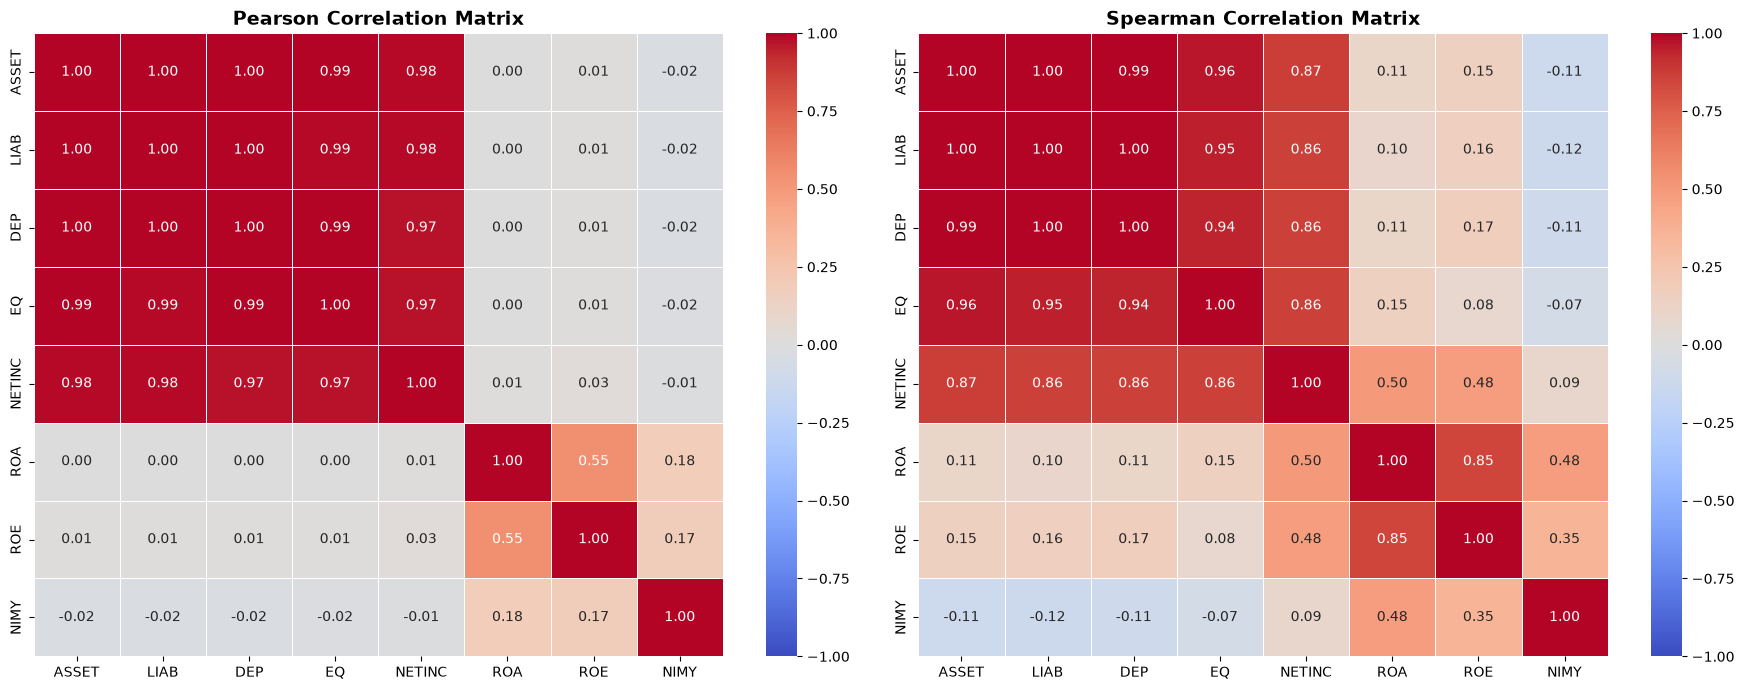

In [50]:
# 14.2 Visualizing Financial Indicator Correlations

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Pearson correlation heatmap
sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5,
    ax=axes[0]
)

axes[0].set_title(
    "Pearson Correlation Matrix",
    fontsize=14,
    fontweight="bold"
)

# Spearman correlation heatmap
sns.heatmap(
    spearman_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5,
    ax=axes[1]
)

axes[1].set_title(
    "Spearman Correlation Matrix",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## 14.3 Outlier Detection using the IQR Method

### Objective
Identify unusually high and low financial observations among FDIC-insured institutions.

### Analysis
- Apply the Interquartile Range (IQR) method.
- Identify lower and upper outlier boundaries.
- Count outliers for selected financial indicators.
- Compare the extent of outliers across financial variables.

### Methodological Consideration
Outliers are not automatically errors or signs of financial distress. They may reflect institution size, unusual financial events, reporting differences or extreme denominator effects. No observations will be removed at this stage.

In [51]:
# 14.3 Outlier Detection using the IQR Method

outlier_columns = [
    "ASSET",
    "LIAB",
    "DEP",
    "EQ",
    "NETINC",
    "ROA",
    "ROE",
    "NIMY"
]

outlier_results = []

for column in outlier_columns:

    data = q2[column].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_bound) |
        (data > upper_bound)
    ]

    outlier_results.append({
        "Metric": column,
        "Valid Records": len(data),
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": (
            len(outliers) / len(data)
        ) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

print("IQR-BASED OUTLIER DETECTION")
print("=" * 100)

print(
    outlier_summary.round(3).to_string(index=False)
)

IQR-BASED OUTLIER DETECTION
Metric  Valid Records         Q1         Q3        IQR  Lower Bound  Upper Bound  Outlier Count  Outlier Percentage
 ASSET           4247 173010.000 992939.500 819929.500 -1056884.250  2222833.750            567              13.351
  LIAB           4247 149786.000 888168.500 738382.500  -957787.750  1995742.250            556              13.092
   DEP           4247 144353.500 831053.500 686700.000  -885696.500  1861103.500            559              13.162
    EQ           4238  18905.250 107628.000  88722.750  -114178.875   240712.125            557              13.143
NETINC           4238    816.000   6358.000   5542.000    -7497.000    14671.000            551              13.001
   ROA           4247      0.817      1.642      0.825       -0.420        2.879            232               5.463
   ROE           4237      7.570     15.710      8.140       -4.640       27.920            198               4.673
  NIMY           4247      3.371      4.353 

## 14.4 Visual Analysis of Financial Outliers

### Objective
Visually examine the distribution of financial indicators and identify extreme observations.

### Analysis
- Generate boxplots for absolute financial amounts.
- Generate separate boxplots for profitability indicators.
- Compare the spread, median and extreme observations.

### Methodological Consideration
Financial amounts and ratios have different scales. Therefore, they are visualized separately to improve readability. Extreme observations are retained for further investigation.

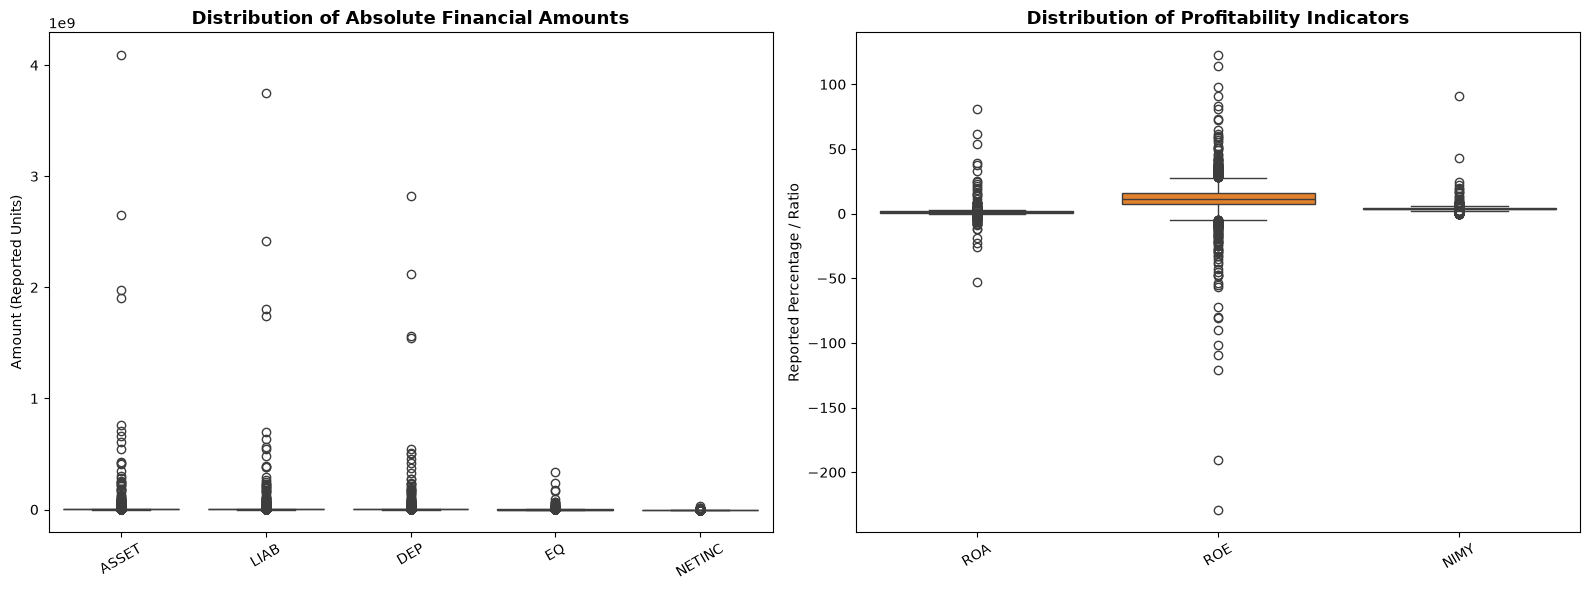

In [52]:
# 14.4 Visual Analysis of Financial Outliers

import matplotlib.pyplot as plt
import seaborn as sns

# Separate financial amounts and ratios
amount_columns = [
    "ASSET",
    "LIAB",
    "DEP",
    "EQ",
    "NETINC"
]

ratio_columns = [
    "ROA",
    "ROE",
    "NIMY"
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot for financial amounts
sns.boxplot(
    data=q2[amount_columns],
    ax=axes[0]
)

axes[0].set_title(
    "Distribution of Absolute Financial Amounts",
    fontsize=13,
    fontweight="bold"
)

axes[0].set_ylabel("Amount (Reported Units)")
axes[0].tick_params(axis="x", rotation=30)

# Boxplot for financial ratios
sns.boxplot(
    data=q2[ratio_columns],
    ax=axes[1]
)

axes[1].set_title(
    "Distribution of Profitability Indicators",
    fontsize=13,
    fontweight="bold"
)

axes[1].set_ylabel("Reported Percentage / Ratio")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 14.5 Detailed Investigation of Extreme Financial Values

### Objective
Examine institutions with unusually high and low profitability indicators.

### Analysis
- Identify the five highest and five lowest ROA observations.
- Identify the five highest and five lowest ROE observations.
- Identify the five highest and five lowest NIMY observations.
- Retain institution names and FDIC certificate numbers for traceability.

### Methodological Consideration
Extreme values require further investigation and are not automatically evidence of financial distress or reporting errors. ROA and ROE can be affected by denominator effects, while NIMY reflects interest margin performance rather than overall profitability.

In [53]:
# 14.5 Detailed Investigation of Extreme Financial Values

extreme_columns = ["ROA", "ROE", "NIMY"]

extreme_records = []

for column in extreme_columns:

    valid_data = q2[
        ["CERT", "NAME", "BKCLASS", column]
    ].dropna(subset=[column])

    # Five lowest observations
    lowest = valid_data.nsmallest(5, column).copy()
    lowest["Metric"] = column
    lowest["Extreme Type"] = "Lowest"

    # Five highest observations
    highest = valid_data.nlargest(5, column).copy()
    highest["Metric"] = column
    highest["Extreme Type"] = "Highest"

    extreme_records.append(lowest)
    extreme_records.append(highest)

extreme_values = pd.concat(
    extreme_records,
    ignore_index=True
)

extreme_values = extreme_values[
    [
        "Metric",
        "Extreme Type",
        "CERT",
        "NAME",
        "BKCLASS",
        extreme_columns[0]
        if False else "ROA"
    ]
    if False else [
        "Metric",
        "Extreme Type",
        "CERT",
        "NAME",
        "BKCLASS",
        "ROA",
        "ROE",
        "NIMY"
    ]
]

print("EXTREME PROFITABILITY OBSERVATIONS")
print("=" * 100)

print(extreme_values.to_string(index=False))

EXTREME PROFITABILITY OBSERVATIONS
Metric Extreme Type  CERT                         NAME BKCLASS        ROA     ROE      NIMY
   ROA       Lowest 59360           HOUSTON BANK&TRUST      NM -53.114380     NaN       NaN
   ROA       Lowest 59190      VARO BANK NATIONAL ASSN       N -25.677126     NaN       NaN
   ROA       Lowest 59365   GENERATIONS COMMUNITY BANK      NM -22.639655     NaN       NaN
   ROA       Lowest 30357   STREATOR HOME SAVINGS BANK      SI -18.930062     NaN       NaN
   ROA       Lowest 26816             LIBERTY BANK INC      NM -11.624441     NaN       NaN
   ROA      Highest 35164        CAPITAL BANK&TRUST CO      SB  81.137916     NaN       NaN
   ROA      Highest 34619                     ITS BANK      NM  61.629120     NaN       NaN
   ROA      Highest 35388         SEI PRIVATE TRUST CO      SB  53.727158     NaN       NaN
   ROA      Highest 57093 NORTHWESTERN MUTUAL WEALTH M      SB  38.879417     NaN       NaN
   ROA      Highest 59177     SQUARE FINL SER

In [54]:
# 14.5 Detailed Investigation of Extreme Financial Values

extreme_columns = ["ROA", "ROE", "NIMY"]

extreme_records = []

for column in extreme_columns:

    valid_data = q2[
        ["CERT", "NAME", "BKCLASS", column]
    ].dropna(subset=[column])

    for label, data in [
        ("Lowest", valid_data.nsmallest(5, column)),
        ("Highest", valid_data.nlargest(5, column))
    ]:

        for _, row in data.iterrows():

            extreme_records.append({
                "Metric": column,
                "Extreme Type": label,
                "CERT": row["CERT"],
                "Institution": row["NAME"],
                "BKCLASS": row["BKCLASS"],
                "Value": row[column]
            })

extreme_values = pd.DataFrame(extreme_records)

print("EXTREME PROFITABILITY OBSERVATIONS")
print("=" * 100)

for column in extreme_columns:

    print(f"\n{column}")
    print("-" * 80)

    print(
        extreme_values[
            extreme_values["Metric"] == column
        ].round(4).to_string(index=False)
    )

EXTREME PROFITABILITY OBSERVATIONS

ROA
--------------------------------------------------------------------------------
Metric Extreme Type  CERT                  Institution BKCLASS    Value
   ROA       Lowest 59360           HOUSTON BANK&TRUST      NM -53.1144
   ROA       Lowest 59190      VARO BANK NATIONAL ASSN       N -25.6771
   ROA       Lowest 59365   GENERATIONS COMMUNITY BANK      NM -22.6397
   ROA       Lowest 30357   STREATOR HOME SAVINGS BANK      SI -18.9301
   ROA       Lowest 26816             LIBERTY BANK INC      NM -11.6244
   ROA      Highest 35164        CAPITAL BANK&TRUST CO      SB  81.1379
   ROA      Highest 34619                     ITS BANK      NM  61.6291
   ROA      Highest 35388         SEI PRIVATE TRUST CO      SB  53.7272
   ROA      Highest 57093 NORTHWESTERN MUTUAL WEALTH M      SB  38.8794
   ROA      Highest 59177     SQUARE FINL SERVICES INC      NM  37.8493

ROE
--------------------------------------------------------------------------------
M

## 14.5.1 Validating Extreme Financial Observations

### Objective
Investigate the underlying financial values associated with extreme ROA, ROE and NIMY observations.

### Analysis
- Examine assets, equity and net income.
- Examine net interest income and NIMY.
- Identify possible denominator effects and unusual reported values.
- Retain the original observations without automatically classifying them as errors.

### Methodological Consideration
Extreme ratios must be interpreted alongside their underlying financial amounts. This validation is exploratory and does not independently establish the accuracy of reported figures.

In [55]:
# 14.5.1 Validating Extreme Financial Observations

extreme_certificates = (
    extreme_values["CERT"]
    .drop_duplicates()
)

validation_columns = [
    "CERT",
    "NAME",
    "BKCLASS",
    "ASSET",
    "EQ",
    "NETINC",
    "NIM",
    "NIMY",
    "ROA",
    "ROE"
]

extreme_validation = q2[
    validation_columns
].loc[
    q2["CERT"].isin(extreme_certificates)
].copy()

print("UNDERLYING FINANCIAL VALUES OF EXTREME OBSERVATIONS")
print("=" * 110)

print(
    extreme_validation.sort_values(
        by="CERT"
    ).round(4).to_string(index=False)
)

UNDERLYING FINANCIAL VALUES OF EXTREME OBSERVATIONS
 CERT                         NAME BKCLASS   ASSET        EQ   NETINC      NIM    NIMY      ROA     ROE
 3225               TITAN BANK N A       N  896113  113344.0  47643.0  23053.0  5.4910  10.9661   97.55
 8681       LAMONT BANK OF ST JOHN      NM   51124     919.0  -1698.0    419.0  1.6236  -6.2251 -228.84
10597                     TBO BANK      NM  224834   22702.0    838.0  90679.0 91.0612   0.7383    7.52
12013    UNION COUNTY SAVINGS BANK      SI 1478885  -23485.0 -10806.0  -2699.0 -0.3679  -1.4500     NaN
17280                BANK OF TIOGA      NM  412068    8579.0   2691.0   4477.0  2.4471   1.3240   83.08
17878            BANK OF LOUISIANA      NM  110293   19208.0   8495.0   2359.0  5.1798  16.1175  122.62
18924               OLD GLORY BANK      NM  276783    6782.0  -7993.0   5171.0  3.9870  -5.8947 -190.79
25054         SUMMIT NATIONAL BANK       N   65941    1581.0   -773.0    744.0  2.2364  -2.1977 -101.58
25620       

## 14.6 Institution Size-Based Financial Analysis

### Objective
Examine differences in financial characteristics across institutions of different asset sizes.

### Analysis
- Divide institutions into four asset-based quartiles.
- Compare the number of institutions in each group.
- Examine median profitability and balance-sheet ratios.
- Compare the distribution of financial screening indicators across size groups.

### Methodological Consideration
Institution size groups are defined using Q2 asset quartiles. Median values are used to reduce the influence of extreme observations. These groups are descriptive and do not represent official FDIC size classifications.

In [56]:
# 14.6 Institution Size-Based Financial Analysis

size_data = health_data.copy()

# Remove institutions with missing asset values
size_data = size_data.dropna(subset=["ASSET"]).copy()

# Divide institutions into four asset-size groups
size_data["SIZE_GROUP"] = pd.qcut(
    size_data["ASSET"].rank(method="first"),
    q=4,
    labels=[
        "Small",
        "Medium",
        "Large",
        "Very Large"
    ]
)

# Summarize each group
size_summary = size_data.groupby(
    "SIZE_GROUP",
    observed=False
).agg(
    Institutions=("CERT", "count"),
    Median_Assets=("ASSET", "median"),
    Median_Equity_Ratio=("EQUITY_ASSET_RATIO", "median"),
    Median_Liability_Ratio=("LIABILITY_ASSET_RATIO", "median"),
    Median_ROA=("ROA", "median"),
    Median_ROE=("ROE", "median"),
    Median_NIMY=("NIMY", "median")
).reset_index()

print("FINANCIAL CHARACTERISTICS BY INSTITUTION SIZE")
print("=" * 110)

print(size_summary.round(3).to_string(index=False))

FINANCIAL CHARACTERISTICS BY INSTITUTION SIZE
SIZE_GROUP  Institutions  Median_Assets  Median_Equity_Ratio  Median_Liability_Ratio  Median_ROA  Median_ROE  Median_NIMY
     Small          1062        98113.5               11.498                  88.505       1.091        9.62        3.886
    Medium          1062       266427.5               10.299                  89.701       1.235       11.95        3.991
     Large          1061       591890.0               10.207                  89.788       1.289       12.55        3.906
Very Large          1062      2357180.0               10.493                  89.527       1.250       11.96        3.682


In [57]:
print(
    size_summary[
        size_summary["SIZE_GROUP"] == "Very Large"
    ].round(3).to_string(index=False)
)

SIZE_GROUP  Institutions  Median_Assets  Median_Equity_Ratio  Median_Liability_Ratio  Median_ROA  Median_ROE  Median_NIMY
Very Large          1062      2357180.0               10.493                  89.527        1.25       11.96        3.682


## 14.7 Financial Screening Signals by Institution Size

### Objective
Examine the distribution of exploratory financial screening signals across institution-size groups.

### Analysis
- Combine asset-based size groups with financial screening indicators.
- Calculate the number of institutions with capital-position signals.
- Calculate the number with profitability signals.
- Measure the proportion with at least one screening signal.

### Methodological Consideration
The screening indicators are exploratory project-defined measures, not official FDIC ratings or regulatory classifications. Differences across size groups are descriptive and should not be interpreted as evidence that a particular size category is inherently riskier.

In [60]:
print("COMPLETE_SCREENING COLUMNS:")
print(complete_screening.columns.tolist())

print("\nFIRST 5 ROWS:")
print(complete_screening.head())

COMPLETE_SCREENING COLUMNS:
['CERT', 'NAME', 'BKCLASS', 'ASSET', 'LIAB', 'DEP', 'EQ', 'NETINC', 'ROA', 'ROE', 'NIMY', 'EQUITY_ASSET_RATIO', 'LIABILITY_ASSET_RATIO', 'NEGATIVE_EQUITY', 'NEGATIVE_NET_INCOME', 'NEGATIVE_ROA', 'NEGATIVE_ROE', 'NEGATIVE_NIMY', 'LOW_EQUITY_RATIO', 'HIGH_LIABILITY_RATIO', 'WARNING_SIGNAL_COUNT', 'INCOMPLETE_SCREENING_DATA', 'CAPITAL_POSITION_SIGNAL', 'PROFITABILITY_SIGNAL', 'GROUPED_SIGNAL_COUNT']

FIRST 5 ROWS:
   CERT                        NAME BKCLASS      ASSET       LIAB        DEP  \
0    14  STATE STREET BANK&TRUST CO      SM  412620000  383448000  326247000   
1    35                  AUBURNBANK      SM    1085002     994121     990462   
2    39        ROBERTSON BANKING CO      NM     462662     411609     399516   
3    41          PHENIX-GIRARD BANK      NM     342259     333299     323551   
4    49           BANK OF EVERGREEN      NM      78111      69019      68562   

           EQ     NETINC       ROA    ROE  ...  NEGATIVE_ROA  NEGATIVE_ROE  

In [61]:
# 14.7 Financial Screening Signals by Institution Size

# Merge institution size groups with complete screening records
size_screening = size_data.merge(
    complete_screening[
        [
            "CERT",
            "CAPITAL_POSITION_SIGNAL",
            "PROFITABILITY_SIGNAL",
            "GROUPED_SIGNAL_COUNT"
        ]
    ],
    on="CERT",
    how="inner"
)

# Calculate screening summary by size group
size_screening_summary = size_screening.groupby(
    "SIZE_GROUP",
    observed=False
).agg(
    Institutions=("CERT", "count"),
    Capital_Signals=("CAPITAL_POSITION_SIGNAL", "sum"),
    Profitability_Signals=("PROFITABILITY_SIGNAL", "sum"),
    Institutions_With_Signals=(
        "GROUPED_SIGNAL_COUNT",
        lambda x: (x > 0).sum()
    )
).reset_index()

# Calculate percentages
size_screening_summary["Capital_Signal_Percentage"] = (
    size_screening_summary["Capital_Signals"] /
    size_screening_summary["Institutions"]
) * 100

size_screening_summary["Profitability_Signal_Percentage"] = (
    size_screening_summary["Profitability_Signals"] /
    size_screening_summary["Institutions"]
) * 100

size_screening_summary["Any_Signal_Percentage"] = (
    size_screening_summary["Institutions_With_Signals"] /
    size_screening_summary["Institutions"]
) * 100

print("FINANCIAL SCREENING SIGNALS BY INSTITUTION SIZE")
print("=" * 110)

print(
    size_screening_summary.round(2).to_string(index=False)
)

FINANCIAL SCREENING SIGNALS BY INSTITUTION SIZE
SIZE_GROUP  Institutions  Capital_Signals  Profitability_Signals  Institutions_With_Signals  Capital_Signal_Percentage  Profitability_Signal_Percentage  Any_Signal_Percentage
     Small          1061               61                     95                        147                       5.75                             8.95                  13.85
    Medium          1062               65                     30                         92                       6.12                             2.82                   8.66
     Large          1061               53                     36                         82                       5.00                             3.39                   7.73
Very Large          1053               32                     16                         47                       3.04                             1.52                   4.46


## 14.8 Statistical Association Between Institution Size and Screening Signals

### Objective
Determine whether institution size groups are statistically associated with exploratory financial screening signals.

### Analysis
- Construct contingency tables for institution size and capital-position signals.
- Examine institution size and profitability signals.
- Examine institution size and the presence of any screening signal.
- Apply the Chi-square test of independence.
- Calculate Cramér's V to measure association strength.

### Methodological Consideration
Statistical significance does not establish causation or practical importance. Cramér's V is used alongside p-values to assess association strength. Screening indicators remain exploratory and are not official regulatory classifications.

In [64]:
# 14.8 Statistical Association Between Institution Size and Screening Signals
%pip install scipy
import scipy
from scipy.stats import chi2_contingency

print("SciPy version:", scipy.__version__)
print("Chi-square test imported successfully!")

Note: you may need to restart the kernel to use updated packages.
SciPy version: 1.18.1
Chi-square test imported successfully!



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
